# Detecting Hidden Data Leakage
### An automated framework based on dataset and model behaviour — **Adult Income (UCI)** benchmark



---

## Problem
ML results are often inflated by data leakage, yet finding it normally requires full knowledge of the training pipeline. This notebook builds an **automated, pipeline-agnostic detector** that sees only

* the processed train / test splits exactly as given to the model (features, labels, optional timestamp column), and
* the trained model as a **black box** (`predict` / `predict_proba` only) — no code, no logs, no pipeline details,

and measures how reliably it finds **controlled, injected** leakage on the Adult Income data with four model families (Logistic Regression, Random Forest, XGBoost, MLP).

## Leakage types and what applies to this dataset
| # | Leakage type | Injected here? | How |
|---|---|---|---|
| 1 | **Target leakage** – a feature encodes / is derived from the label | ✅ | extra column `leak_feat = y + N(0, σ)`, σ ∈ {1.0, 0.5, 0.15} |
| 2 | **Train–test contamination** – test rows duplicated / near-duplicated in train | ✅ | 1 % / 5 % / 20 % of test rows copied into train (exact and near copies) |
| 3 | **Temporal leakage** – training uses data from after the test period | ❌ **N/A** | Adult has **no time axis** (it is a single census snapshot). The module abstains here (`score = NaN`, `flag = False`) and is unit-tested on *synthetic* timestamps (cell 17) outside the reported results. No fake time axis is invented. The Credit Card notebook, whose data has real timestamps, evaluates this type. |
| 4 | **Preprocessing leakage** – scaling / imputation / encoding fitted on train + test | ✅ | scaler; scaler + imputer; scaler + imputer + frequency-encoder fitted on train + test |

## Detector output (per leakage type)
a leakage **score (0–1)**, a binary **flag**, the **evidence** (suspect features, duplicate row IDs, fingerprints), an overall **verdict** (`clean` / `leaky`) and an **estimated performance inflation**. Signals used: feature–target mutual information, duplicate overlap, adversarial validation, feature ablation, permutation importance, exact scaler / imputer / encoder fingerprints and train–test confidence gaps.

## How to run
1. **Runtime → Run all.** CPU runtime is enough, no Google Drive needed. The data are found in this order: a local file with “adult” in its name in `/content` (UCI `adult.data` / `adult.test`, Kaggle `adult.csv`, or OpenML export, with or without header) → OpenML (`fetch_openml("adult", version=2)`) → the UCI repository → a GitHub mirror. If you want to be independent of the internet, upload the file to `/content` first.
2. Outputs go to `/content/results/` (`results.csv`, `results_with_inflation.csv`, `thresholds.json`, `tables/`, `figures/`) and are zipped for download in the last cell.
3. Set `CFG["QUICK_MODE"] = True` in cell 3 for a smoke run (4 seeds, fewer trees). The benchmark checkpoints after every scenario and **resumes** automatically if the session restarts.

> **Runtime.** The full benchmark is 10 scenarios × 4 models × 10 seeds, plus threshold calibration (5 extra seeds). Not measured yet: expect roughly an hour or more on a free Colab CPU for `N_SEEDS = 10` (Adult has about 2.5x the rows of California Housing); `QUICK_MODE` takes roughly half of that.

## Key design decisions
1. **Label.** `y = 1` if income > 50K (the natural label, ≈ 24 % positive). Every split is stratified, so the class share is the same in train / validation / test.
2. **Data preparation.** `adult.data` + `adult.test` are merged (48,842 rows), `?` becomes a real missing value, **exact duplicate rows are removed** (so that every duplicate found later is an injected one) and `education` is dropped (it is a one-to-one relabelling of `education_num`).
3. **Split.** Stratified random 60 / 20 / 20 train / validation / test, redrawn for every seed. The validation set is used only for XGBoost early stopping and the practitioner check (cell 32). **The detector never sees it.**
4. **Missing values.** `?` entries stay missing in `workclass`, `occupation`, `native_country` (frequency code 0.0). A fixed MCAR mask (5 % in `age` and `fnlwgt`, seed 2024) is applied once before splitting so that mean imputation exists in every scenario and its fingerprint can be tested. These two columns are chosen because they have no natural modal value that would hide an imputation spike. It is data, not a leak.
5. **Clean twin.** Every leaky scenario is compared with the `clean` scenario of the same seed (same split, same test rows). True inflation = metric(leaky) − metric(clean).
6. **Frequency-encoding, mean imputation and scaling are present in *every* scenario**, so the detector cannot separate clean from leaky just from the presence of a preprocessing step.
7. **Thresholds** are calibrated on disjoint seeds (100–104) and frozen *before* the evaluation seeds (0–9) are run.
8. **Metrics.** AUC is the primary metric; average precision (PR-AUC) is reported next to it.

## Known caveats (stated up-front)
* **Temporal leakage is not evaluated** for this dataset (no time axis) and is reported as N/A.
* The `clean` scenario is clean **only with respect to the four injected leak types**.
* Frequency encoding is deliberately simple (it is the encoder whose leakage we inject), so absolute AUCs are lower than for a tuned one-hot pipeline; only differences between scenarios matter here.
* `sex` and `race` are ordinary features in this notebook; it is about leakage, not fairness.
* Wilson confidence intervals treat every (seed, scenario, model) run as independent, but the four models of one scenario share the same data-level evidence, so the intervals are somewhat optimistic.
* Preprocessing leakage barely changes accuracy; it is detected from exact fingerprints, **not** from performance.


---
# PART A — Setup and data
Imports, configuration, loading with schema auto-detection, EDA, label construction and the split builder.

In [ ]:
# ===================================================================
# PART A — SETUP AND DATA
# Cell 2 — Installs and imports (no Google Drive)
# ===================================================================
import importlib, subprocess, sys, os, glob, json, gc, time, hashlib, warnings, math
from dataclasses import dataclass, field

def _ensure(pip_name, import_name=None):
    """pip-install a package only if it cannot be imported."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

_ensure("xgboost")
_ensure("tqdm")

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
import xgboost
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold, KFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, f1_score, log_loss, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import mutual_info_classif
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold"})

# ---- folders -------------------------------------------------------
ROOT = "/content" if os.path.isdir("/content") else os.getcwd()     # Colab, or local Jupyter fallback
RESULTS_DIR = os.path.join(ROOT, "results")
FIG_DIR     = os.path.join(RESULTS_DIR, "figures")
TABLE_DIR   = os.path.join(RESULTS_DIR, "tables")
for _d in (RESULTS_DIR, FIG_DIR, TABLE_DIR):
    os.makedirs(_d, exist_ok=True)

# ---- environment report -------------------------------------------
def _ram_gb():
    try:
        import psutil
        return psutil.virtual_memory().total / 2**30
    except Exception:
        try:
            return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
        except Exception:
            return float("nan")

print("Python      :", sys.version.split()[0])
for _m in (np, pd, scipy, sklearn, xgboost, matplotlib, sns):
    print(f"{_m.__name__:<11}:", _m.__version__)
print("CPU count   :", os.cpu_count())
print(f"RAM         : {_ram_gb():.1f} GB")
print("Working dir :", ROOT)
print("Results dir :", RESULTS_DIR)

Python      : 3.13.18
numpy      : 2.1.3
pandas     : 2.2.3
scipy      : 1.16.3
sklearn    : 1.6.1
xgboost    : 3.4.1
matplotlib : 3.10.0
seaborn    : 0.13.2
CPU count   : 2
RAM         : 12.7 GB
Working dir : /content
Results dir : /content/results


In [ ]:
# ===================================================================
# Cell 3 — Configuration `CFG` (every tunable value lives here)
# ===================================================================
CFG = dict(
    # ---------------- data ----------------
    DATA_PATH=os.path.join(ROOT, "adult.csv"),   # used if present; otherwise a file with 'adult' in its name, otherwise a download (cell 4)

    # ---------------- run size ------------
    QUICK_MODE=False,            # True -> N_SEEDS=4, fewer trees, 3 calibration seeds (smoke run)
    N_SEEDS=10,
    CAL_SEEDS=[100, 101, 102, 103, 104],      # calibration seeds: disjoint from the evaluation seeds
    MASK_SEED=2024,
    RESUME=True,                 # resume results.csv if present (False -> start from scratch)

    # ---------------- split / missingness -------------
    SPLIT=(0.6, 0.2, 0.2),       # train / validation / test
    MCAR_RATE=0.05,
    MCAR_COLS=["age", "fnlwgt"],  # columns without a natural modal value (an imputation spike must stay visible)
    CONTAM_STRATIFY=False,       # True -> contamination copies keep the class mix of the test set (used for rare-positive data)
    TARGET_AUC_TOL=0.03,         # tolerance of the sanity test "single-feature AUC of leak_feat vs theory"

    # ---------------- detector constants --------
    MI_SUBSAMPLE=20000,
    NN_QUERY=4000,               # effective value: min(NN_QUERY, len(test))
    NN_HOLDOUT=4000,             # effective value: min(NN_HOLDOUT, len(train)//3)
    ADV_SUBSAMPLE=20000,
    PERM_ROWS=4000,
    PERM_REPEATS=3,
    TOP_K=5,
    ROUND_DECIMALS=6,
    FP_TOL=1e-7,
    NEW_ID_BASE=10_000_000,      # row_ids given to injected train copies (so ids never reveal the leak)

    # ---------------- thresholds (raised only by cell 24, then frozen) --------
    THRESH=dict(target=0.5, contamination=0.5, temporal=0.5, preprocessing=0.5),

    LEAK_TYPES=["target", "contamination", "temporal", "preprocessing"],
    EVALUATED_TYPES=["target", "contamination", "preprocessing"],   # temporal is N/A (no timestamp)
    MODELS=["logreg", "rf", "xgb", "mlp"],

    # ---------------- scenario matrix (per seed) ------------------
    # params keys:  sigma -> target leak | p, near_frac -> contamination | scopes -> preprocessing fit scope
    SCENARIOS={
        "clean":     dict(type="none",          variant="-", params={}),
        "target_L":  dict(type="target",        variant="L", params=dict(sigma=1.0)),
        "target_M":  dict(type="target",        variant="M", params=dict(sigma=0.5)),
        "target_H":  dict(type="target",        variant="H", params=dict(sigma=0.15)),
        "contam_L":  dict(type="contamination", variant="L", params=dict(p=0.01, near_frac=0.0)),   # all exact
        "contam_M":  dict(type="contamination", variant="M", params=dict(p=0.05, near_frac=0.5)),
        "contam_H":  dict(type="contamination", variant="H", params=dict(p=0.20, near_frac=0.5)),
        "prep_L":    dict(type="preprocessing", variant="L", params=dict(scopes=dict(scale="pool"))),
        "prep_M":    dict(type="preprocessing", variant="M", params=dict(scopes=dict(scale="pool", impute="pool"))),
        "prep_H":    dict(type="preprocessing", variant="H", needs_cat=True,
                          params=dict(scopes=dict(scale="pool", impute="pool", encode="pool"))),
    },
)
if CFG["QUICK_MODE"]:
    CFG["N_SEEDS"] = 4
    CFG["CAL_SEEDS"] = CFG["CAL_SEEDS"][:3]
CFG["EVAL_SEEDS"] = list(range(CFG["N_SEEDS"]))
assert not set(CFG["EVAL_SEEDS"]) & set(CFG["CAL_SEEDS"]), "calibration and evaluation seeds must be disjoint"

print("QUICK_MODE :", CFG["QUICK_MODE"], "| evaluation seeds:", CFG["EVAL_SEEDS"], "| calibration seeds:", CFG["CAL_SEEDS"])
print("Scenarios  :", list(CFG["SCENARIOS"]))


QUICK_MODE : False | evaluation seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | calibration seeds: [100, 101, 102, 103, 104]
Scenarios  : ['clean', 'target_L', 'target_M', 'target_H', 'contam_L', 'contam_M', 'contam_H', 'prep_L', 'prep_M', 'prep_H']


In [ ]:
# ===================================================================
# Cell 4 — Load Adult Income (local file -> OpenML -> UCI -> GitHub mirror) and normalise the schema
# ===================================================================
import re, urllib.request

ADULT_RAW_COLS = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status", "occupation",
                  "relationship", "race", "sex", "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"]

def _norm(c):
    return re.sub(r"[^0-9a-z]+", "_", str(c).strip().lower()).strip("_")

def _download(url, dest, timeout=90):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=timeout) as r, open(dest, "wb") as fh:
        fh.write(r.read())
    return dest

def _read_adult_file(path):
    """CSV with or without a header line (UCI 'adult.data' and 'adult-all.csv' have none; 'adult.test' starts with a comment)."""
    with open(path, "r", errors="ignore") as fh:
        lines = [fh.readline() for _ in range(3)]
    skip = 1 if lines[0].startswith("|") else 0
    first = lines[skip].split(",")[0].strip()
    if first.replace(".", "", 1).isdigit():                                   # no header
        return pd.read_csv(path, header=None, names=ADULT_RAW_COLS, skiprows=skip, skipinitialspace=True)
    return pd.read_csv(path, skiprows=skip, skipinitialspace=True)

def _locate_local():
    if os.path.exists(CFG["DATA_PATH"]):
        return CFG["DATA_PATH"]
    hits = sorted(f for f in glob.glob(os.path.join(ROOT, "*"))
                  if "adult" in os.path.basename(f).lower() and f.lower().endswith((".csv", ".data", ".txt", ".test")))
    if len(hits) > 1:
        print("More than one candidate found, using the first:", [os.path.basename(h) for h in hits])
    return hits[0] if hits else None

def load_adult_frame():
    path = _locate_local()
    if path is not None:
        return _read_adult_file(path), f"local file {os.path.basename(path)}"
    errors = []
    try:                                                                       # 1. OpenML
        from sklearn.datasets import fetch_openml
        frame = fetch_openml("adult", version=2, as_frame=True).frame.copy()
        return frame, "OpenML adult (version 2)"
    except Exception as e:
        errors.append(f"OpenML: {type(e).__name__}")
    try:                                                                       # 2. UCI repository (train + test file)
        base = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
        parts = []
        for fn, skip in (("adult.data", 0), ("adult.test", 1)):
            dest = _download(base + fn, os.path.join(ROOT, "uci_" + fn.split(".")[1] + ".tmp"))
            parts.append(pd.read_csv(dest, header=None, names=ADULT_RAW_COLS, skiprows=skip, skipinitialspace=True))
        return pd.concat(parts, ignore_index=True), "UCI adult.data + adult.test"
    except Exception as e:
        errors.append(f"UCI: {type(e).__name__}")
    try:                                                                       # 3. GitHub mirror (jbrownlee/Datasets)
        dest = _download("https://raw.githubusercontent.com/jbrownlee/Datasets/master/adult-all.csv", os.path.join(ROOT, "adult-all.csv"))
        return _read_adult_file(dest), "GitHub mirror adult-all.csv"
    except Exception as e:
        errors.append(f"GitHub mirror: {type(e).__name__}")
    raise FileNotFoundError(
        "Could not find or download the Adult file (" + "; ".join(errors) + ").\n"
        "Upload adult.csv / adult.data (+ adult.test) to /content (left sidebar -> Files -> Upload) and re-run this cell.")

df_orig, DATA_SOURCE = load_adult_frame()
SCHEMA = "adult"
df_orig.columns = [_norm(c) for c in df_orig.columns]
if "income" not in df_orig.columns and "class" in df_orig.columns:             # OpenML calls the label 'class'
    df_orig = df_orig.rename(columns={"class": "income"})
_missing = [c for c in ADULT_RAW_COLS if c not in df_orig.columns]
assert not _missing, f"Adult schema expected but columns are missing: {_missing}. Columns found: {list(df_orig.columns)}"
print(f"Loaded Adult from {DATA_SOURCE}  ->  {df_orig.shape[0]:,} rows x {df_orig.shape[1]} columns")

df_raw = df_orig[ADULT_RAW_COLS].copy()
for _c in df_raw.columns:                                                      # strip blanks, '?' -> missing
    if not pd.api.types.is_numeric_dtype(df_raw[_c]):
        df_raw[_c] = df_raw[_c].astype("object").map(lambda v: v.strip() if isinstance(v, str) else v)
df_raw = df_raw.replace("?", np.nan)
df_raw["income"] = df_raw["income"].astype(str).str.strip().str.rstrip(".")
assert set(df_raw["income"].unique()) <= {"<=50K", ">50K"}, f"unexpected income labels: {df_raw['income'].unique()}"
NUM_RAW = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
df_raw[NUM_RAW] = df_raw[NUM_RAW].apply(pd.to_numeric, errors="coerce").astype(float)

n_before = len(df_raw)
df_raw = df_raw.drop_duplicates().reset_index(drop=True)                      # exact duplicate rows (features + label)
print(f"Removed {n_before - len(df_raw)} exact duplicate rows -> {len(df_raw):,} rows (so every duplicate found later is an injected one).")
df_raw = df_raw.drop(columns=["education"])                                   # one-to-one relabelling of education_num
HAS_CATEGORICAL = True
display(df_raw.head(3))
print("Canonical columns:", list(df_raw.columns))
print(f"Row count: {len(df_raw):,}  ({'OK, close to 48,842 minus duplicates' if 47000 <= len(df_raw) <= 49000 else 'WARNING: expected about 48,800 rows'})")


Loaded Adult from OpenML adult (version 2)  ->  48,842 rows x 15 columns
Removed 52 exact duplicate rows -> 48,790 rows (so every duplicate found later is an injected one).


,age,workclass,fnlwgt,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,25.0,Private,226802.0,7.0,Never-married,Machine-op-inspct,Own-child,Black,Male,0.0,0.0,40.0,United-States,<=50K
1,38.0,Private,89814.0,9.0,Married-civ-spouse,Farming-fishing,Husband,White,Male,0.0,0.0,50.0,United-States,<=50K
2,28.0,Local-gov,336951.0,12.0,Married-civ-spouse,Protective-serv,Husband,White,Male,0.0,0.0,40.0,United-States,>50K


Canonical columns: ['age', 'workclass', 'fnlwgt', 'education_num', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income']
Row count: 48,790  (OK, close to 48,842 minus duplicates)


Missing values (natural '?' entries, before the MCAR top-up in cell 6):


,n_missing,pct_missing
workclass,2795,5.73
occupation,2805,5.75
native_country,856,1.75


Descriptive statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
age,48790.0,38.653,13.708,17.0,28.0,37.0,48.00,90.0
fnlwgt,48790.0,189668.999,105617.231,12285.0,117555.0,178138.5,237606.25,1490400.0
education_num,48790.0,10.079,2.570,1.0,9.0,10.0,12.00,16.0
capital_gain,48790.0,1080.218,7455.906,0.0,0.0,0.0,0.00,99999.0
capital_loss,48790.0,87.596,403.209,0.0,0.0,0.0,0.00,4356.0
hours_per_week,48790.0,40.426,12.393,1.0,40.0,40.0,45.00,99.0


Cardinality of the categorical columns:


,workclass,marital_status,occupation,relationship,race,sex,native_country
n_categories,8,7,14,6,5,2,41



Duplicate rows in the prepared file: 0  (expected 0 after de-duplication)
Positive class (income > 50K): 23.9%  |  capital_gain == 0 for 91.7% of the rows, capital_loss == 0 for 95.3%


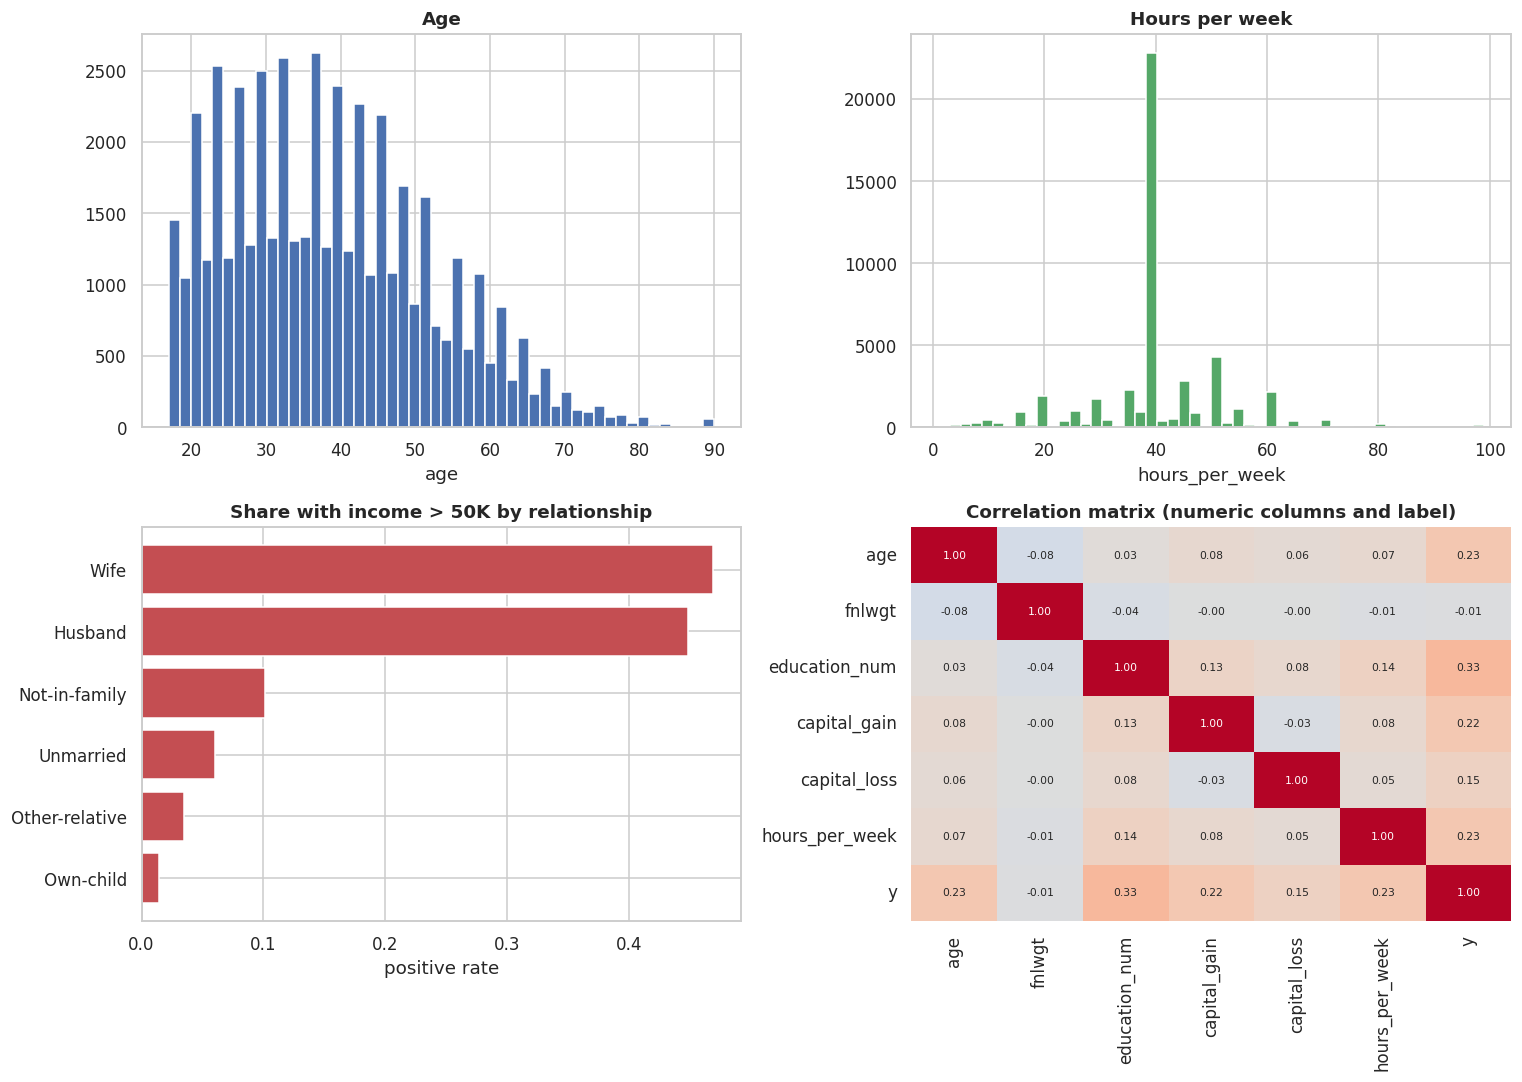

In [ ]:
# ===================================================================
# Cell 5 — Validation and EDA
# ===================================================================
miss = df_raw.isna().sum().to_frame("n_missing")
miss["pct_missing"] = (100 * miss["n_missing"] / len(df_raw)).round(2)
print("Missing values (natural '?' entries, before the MCAR top-up in cell 6):")
display(miss[miss.n_missing > 0])
print("Descriptive statistics (numeric columns):")
display(df_raw.select_dtypes(include=[np.number]).describe().T.round(3))
print("Cardinality of the categorical columns:")
display(df_raw.select_dtypes(exclude=[np.number]).drop(columns=["income"]).nunique().to_frame("n_categories").T)

N_DUP_ROWS = int(df_raw.duplicated().sum())
print(f"\nDuplicate rows in the prepared file: {N_DUP_ROWS}  (expected 0 after de-duplication)")
pos_rate = float((df_raw["income"] == ">50K").mean())
print(f"Positive class (income > 50K): {100 * pos_rate:.1f}%  |  capital_gain == 0 for {100 * (df_raw['capital_gain'] == 0).mean():.1f}% of the rows, "
      f"capital_loss == 0 for {100 * (df_raw['capital_loss'] == 0).mean():.1f}%")

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0, 0].hist(df_raw["age"].dropna(), bins=50, color="#4C72B0"); ax[0, 0].set_title("Age"); ax[0, 0].set_xlabel("age")
ax[0, 1].hist(df_raw["hours_per_week"], bins=50, color="#55A868"); ax[0, 1].set_title("Hours per week"); ax[0, 1].set_xlabel("hours_per_week")
rate = (df_raw.assign(pos=(df_raw["income"] == ">50K").astype(int)).groupby("relationship")["pos"].mean().sort_values())
ax[1, 0].barh(rate.index, rate.values, color="#C44E52"); ax[1, 0].set_title("Share with income > 50K by relationship"); ax[1, 0].set_xlabel("positive rate")
num_for_corr = df_raw.select_dtypes(include=[np.number]).assign(y=(df_raw["income"] == ">50K").astype(int))
sns.heatmap(num_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1, 1], cbar=False, annot_kws={"size": 7})
ax[1, 1].set_title("Correlation matrix (numeric columns and label)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "00_eda.png"), bbox_inches="tight")
plt.show()


In [ ]:
# ===================================================================
# Cell 6 — Feature preparation, label, missingness top-up
# ===================================================================
CAT_COLS = ["workclass", "marital_status", "occupation", "relationship", "race", "sex", "native_country"]
NUM_COLS = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
TS_COL = None                                                     # Adult has no timestamp -> temporal leakage is N/A
NON_FEATURE = ("row_id", "y")                                     # columns that are never model features
CONT_RAW = list(NUM_COLS)                                         # numeric columns -> used for near-duplicate jitter
FEATURE_COLS = CAT_COLS + NUM_COLS
AUC_RANGE = (0.80, 0.98)                                          # plausible clean test AUC (sanity warning only)

data = df_raw.copy().reset_index(drop=True)
data.insert(0, "row_id", np.arange(len(data)))                    # 1. unique row id
data["y"] = (data["income"] == ">50K").astype(int)                # 2. natural label
data = data[["row_id"] + FEATURE_COLS + ["y"]]                    # 3. column order: ids, features, label

# 4. fixed MCAR mask: reach >= MCAR_RATE missing in each configured column (natural NaNs are kept)
mask_rng = np.random.default_rng(CFG["MASK_SEED"])
for col in CFG["MCAR_COLS"]:
    assert col in data.columns, f"MCAR column {col!r} not found"
    target_n = int(math.ceil(CFG["MCAR_RATE"] * len(data)))
    already = int(data[col].isna().sum())
    if already < target_n:
        observed = np.flatnonzero(data[col].notna().to_numpy())
        pick = mask_rng.choice(observed, size=target_n - already, replace=False)
        data.loc[pick, col] = np.nan
miss_rate = data[CFG["MCAR_COLS"]].isna().mean().round(4)
print("Final missing rate per masked column:\n", miss_rate.to_string())
print("Other columns with NaN:", [c for c in FEATURE_COLS if c not in CFG["MCAR_COLS"] and data[c].isna().any()] or "none")

assert 0.15 < data["y"].mean() < 0.35, f"label share off: {data['y'].mean():.3f}"
print(f"\nLabel rule: y = 1 if income > 50K   |   mean(y) = {data['y'].mean():.4f}")
print("Categorical columns :", CAT_COLS)
print("Numeric columns     :", NUM_COLS)
print("`data` shape        :", data.shape, "(row_id + features + y)")


Final missing rate per masked column:
 age       0.05
fnlwgt    0.05
Other columns with NaN: ['workclass', 'occupation', 'native_country']

Label rule: y = 1 if income > 50K   |   mean(y) = 0.2394
Categorical columns : ['workclass', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Numeric columns     : ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
`data` shape        : (48790, 15) (row_id + features + y)


In [ ]:
# ===================================================================
# Cell 7 — Split builder (stratified 60 / 20 / 20, redrawn for every seed)
# ===================================================================
def make_split(seed):
    """Return (train, val, test, future) DataFrames; `future` is None for this dataset. The same seed always gives the same split."""
    idx = np.arange(len(data))
    y_all = data["y"].to_numpy()
    f_train, f_val, f_test = CFG["SPLIT"]
    tr_idx, rest_idx = train_test_split(idx, test_size=f_val + f_test, stratify=y_all, random_state=seed)
    val_idx, te_idx = train_test_split(rest_idx, test_size=f_test / (f_val + f_test), stratify=y_all[rest_idx], random_state=seed)
    take = lambda ii: data.iloc[np.sort(ii)].reset_index(drop=True)
    return take(tr_idx), take(val_idx), take(te_idx), None

# ---- checks ---------------------------------------------------------
_tr, _va, _te, _fu = make_split(0)
_ids = [set(d["row_id"]) for d in (_tr, _va, _te)]
assert not (_ids[0] & _ids[1]) and not (_ids[0] & _ids[2]) and not (_ids[1] & _ids[2]), "row_id overlap between splits"
assert len(_ids[0]) + len(_ids[1]) + len(_ids[2]) == len(data), "split does not cover the data"
_bal = [d["y"].mean() for d in (_tr, _va, _te)]
assert max(_bal) - min(_bal) < 0.01, f"class balance differs by more than 1%: {_bal}"
_again = make_split(0)
assert all(a["row_id"].equals(b["row_id"]) for a, b in zip((_tr, _va, _te), _again[:3])), "split not reproducible"
_other = make_split(1)
assert not _tr["row_id"].equals(_other[0]["row_id"]), "different seeds must give different splits"
print(f"Split sizes (seed 0): train={len(_tr):,}  val={len(_va):,}  test={len(_te):,}")
print("Positive-class share :", [round(b, 4) for b in _bal])
print("PASS: no row_id overlap, balance within 1%, reproducible, seed-dependent.")
del _tr, _va, _te, _fu, _ids, _again, _other


Split sizes (seed 0): train=29,274  val=9,758  test=9,758
Positive-class share : [np.float64(0.2394), np.float64(0.2394), np.float64(0.2394)]
PASS: no row_id overlap, balance within 1%, reproducible, seed-dependent.


---
# PART B — Pipeline, injection, scenarios, models
A preprocessing pipeline with a configurable **fit scope** (train vs train+test), the leakage injectors, the scenario factory (every leaky scenario has a clean twin with the same split), the four models, a black-box wrapper, sanity tests and the clean baseline.

In [ ]:
# ===================================================================
# PART B — PIPELINE, INJECTION, SCENARIOS, MODELS
# Cell 8 — Preprocessing pipeline with configurable fit scope
# ===================================================================
class Pipeline:
    """frequency-encode -> mean-impute -> standardise, each step fitted on 'train' or on 'pool' (= train + test).
    Validation never takes part in any fit. Not related to sklearn.pipeline.Pipeline."""

    def __init__(self, scopes=None):
        self.scopes = dict(encode="train", impute="train", scale="train")
        self.scopes.update(scopes or {})
        assert set(self.scopes) == {"encode", "impute", "scale"}
        assert all(v in ("train", "pool") for v in self.scopes.values())

    def fit(self, train, test):
        feat = [c for c in train.columns if c not in NON_FEATURE]
        self.cat_cols = [c for c in feat if c in CAT_COLS]
        self.num_cols = [c for c in feat if c not in self.cat_cols]
        pool = pd.concat([train, test], ignore_index=True) if "pool" in self.scopes.values() else None
        fit_set = {step: (pool if scope == "pool" else train) for step, scope in self.scopes.items()}

        # (1) frequency encoding: value = share of rows of the fit set that have the category
        self.enc_maps = {}
        for c in self.cat_cols:
            fs = fit_set["encode"][c]
            self.enc_maps[c] = (fs.value_counts(dropna=True) / len(fs)).to_dict()
        # (2) mean imputation from the observed values of the fit set
        self.impute_means = {c: float(np.nanmean(fit_set["impute"][c].to_numpy(dtype=float))) for c in self.num_cols}
        # (3) standardisation fitted on the *imputed* fit set (manual numpy, ddof=0, std 0 -> 1)
        fs_num = self._imputed_numeric(fit_set["scale"])
        self.mu = fs_num.mean(axis=0)
        sd = fs_num.std(axis=0, ddof=0)
        self.sd = np.where(sd == 0, 1.0, sd)
        self.feature_names = [f"{c}_freq" for c in self.cat_cols] + list(self.num_cols)
        return self

    def _imputed_numeric(self, df):
        X = df[self.num_cols].to_numpy(dtype=float).copy()
        for j, c in enumerate(self.num_cols):
            X[np.isnan(X[:, j]), j] = self.impute_means[c]
        return X

    def transform(self, df):
        parts = []
        for c in self.cat_cols:                                    # encoded columns are NOT scaled; unseen -> 0.0
            parts.append(df[c].map(self.enc_maps[c]).fillna(0.0).to_numpy(dtype=float).reshape(-1, 1))
        parts.append((self._imputed_numeric(df) - self.mu) / self.sd)
        return np.hstack(parts).astype(np.float64)

# ---- checks: scope 'train' -> train columns have mean 0, std 1, no NaN ----
_tr, _va, _te, _fu = make_split(0)
_p = Pipeline().fit(_tr, _te)
_Xtr, _Xte = _p.transform(_tr), _p.transform(_te)
_k = len(_p.cat_cols)
assert not np.isnan(_Xtr).any() and not np.isnan(_Xte).any(), "NaN after transform"
assert np.abs(_Xtr[:, _k:].mean(0)).max() < 1e-9 and np.abs(_Xtr[:, _k:].std(0) - 1).max() < 1e-9, "train-fit scaler is not exact"
assert np.abs(_Xte[:, _k:].mean(0)).max() > 1e-4, "test columns should NOT be exactly standardised under a train-only fit"
print("Pipeline features:", _p.feature_names)
print("PASS: train columns |mean|<1e-9 and |std-1|<1e-9; no NaN after transform.")
del _tr, _va, _te, _fu, _p, _Xtr, _Xte

Pipeline features: ['workclass_freq', 'marital_status_freq', 'occupation_freq', 'relationship_freq', 'race_freq', 'sex_freq', 'native_country_freq', 'age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
PASS: train columns |mean|<1e-9 and |std-1|<1e-9; no NaN after transform.


In [ ]:
# ===================================================================
# Cell 9 — Leakage injectors (act on RAW frames, before the pipeline)
# ===================================================================
def theory_single_feature_auc(sigma):
    """AUC of `y + N(0, sigma)` as a score for y in {0,1}:  Phi(1 / (sigma * sqrt 2))."""
    return float(stats.norm.cdf(1.0 / (sigma * np.sqrt(2.0))))

def inject_target(frames, sigma, rng):
    """Add raw column leak_feat = y + N(0, sigma) to every frame (train, val, test and, if present, the future block)."""
    outs = []
    for df in frames:
        if df is None:
            outs.append(None)
            continue
        d = df.copy()
        d["leak_feat"] = d["y"].to_numpy(dtype=float) + rng.normal(0.0, sigma, size=len(d))
        outs.append(d)
    return outs, {"leak_feature": "leak_feat", "sigma": float(sigma)}

def inject_temporal(train, future, tau, rng):
    """Replace n = round(tau * len(train)) random train rows by rows drawn from the FUTURE block (after the test period).
    Train size is unchanged; the injected rows keep their own (later) timestamps and receive no marker."""
    n = int(round(tau * len(train)))
    assert n <= len(future), f"future block too small ({len(future)} rows) for tau = {tau} (needs {n})"
    src = rng.choice(len(future), size=n, replace=False)
    dst = rng.choice(len(train), size=n, replace=False)
    rows = future.iloc[src].reset_index(drop=True)
    new_train = train.copy()
    for c in train.columns:
        new_train.iloc[dst, new_train.columns.get_loc(c)] = rows[c].to_numpy()
    meta = {"n_future_rows": n, "future_row_ids": rows["row_id"].tolist(), "train_positions": dst.tolist()}
    return new_train, meta

def inject_contamination(train, test, p, near_frac, rng, noise_trunc=3.0, stratify=False):
    """Replace n = round(p*len(test)) random train rows by copies of n test rows (train size unchanged).
    stratify=True keeps the class mix of the test set among the copies (needed when the positive class is rare).
    A fraction `near_frac` of the copies is 'near': every continuous feature gets + N(0, 0.005*column_std)
    (noise truncated at +-3 sd, so a near copy is guaranteed within 0.015*std per column; NaN stays NaN; label and
    timestamp are kept). Injected train rows receive FRESH row_ids so that ids never reveal the leak."""
    n = int(round(p * len(test)))
    if stratify:
        y_te = test["y"].to_numpy()
        pos_idx, neg_idx = np.flatnonzero(y_te == 1), np.flatnonzero(y_te == 0)
        n_pos = int(min(len(pos_idx), max(1, round(n * len(pos_idx) / len(test)))))
        test_pos = np.concatenate([rng.choice(pos_idx, size=n_pos, replace=False),
                                   rng.choice(neg_idx, size=n - n_pos, replace=False)])
        rng.shuffle(test_pos)
    else:
        test_pos = rng.choice(len(test), size=n, replace=False)
    train_pos = rng.choice(len(train), size=n, replace=False)
    copies = test.iloc[test_pos].reset_index(drop=True).copy()
    n_near = int(round(near_frac * n))
    is_near = np.zeros(n, dtype=bool)
    if n_near > 0:
        is_near[rng.choice(n, size=n_near, replace=False)] = True
    cont_cols = [c for c in train.columns if c not in NON_FEATURE and c not in CAT_COLS]
    max_dev = 0.0
    for c in cont_cols:
        sd = float(np.nanstd(train[c].to_numpy(dtype=float)))
        z = np.clip(rng.normal(0.0, 1.0, size=n), -noise_trunc, noise_trunc)
        vals = copies[c].to_numpy(dtype=float).copy()
        vals[is_near] = vals[is_near] + 0.005 * sd * z[is_near]
        copies[c] = vals
        if is_near.any():
            max_dev = max(max_dev, float(np.max(np.abs(0.005 * z[is_near]))))
    new_ids = CFG["NEW_ID_BASE"] + np.arange(n)
    new_train = train.copy()
    for c in train.columns:
        vals = new_ids if c == "row_id" else copies[c].to_numpy()
        new_train.iloc[train_pos, new_train.columns.get_loc(c)] = vals
    test_ids = test["row_id"].to_numpy()[test_pos]
    meta = {
        "dup_test_row_ids": test_ids.tolist(),
        "dup_test_row_ids_exact": test_ids[~is_near].tolist(),
        "dup_test_row_ids_near": test_ids[is_near].tolist(),
        "dup_train_row_ids": new_ids.tolist(),
        "dup_test_positions": test_pos.tolist(),
        "dup_train_positions": train_pos.tolist(),
        "is_near": is_near.tolist(),
        "n_exact": int(n - n_near), "n_near": int(n_near),
        "max_abs_dev_in_std": max_dev,
    }
    return new_train, test.copy(), meta

# Preprocessing leakage is not an injector: it is a Pipeline variant (see CFG['SCENARIOS'] and cell 10).

# ---- checks: the test frame is untouched (apart from the extra column for target leakage) ----
_tr, _va, _te, _fu = make_split(0)
_r = np.random.default_rng(0)
(_a, _b, _c, _d), _m = inject_target((_tr, _va, _te, _fu), 0.5, _r)
assert _c.drop(columns=["leak_feat"]).equals(_te), "target injector changed the test features"
assert (_d is None) == (_fu is None)
_t2, _te2, _m2 = inject_contamination(_tr, _te, 0.05, 0.5, _r, stratify=CFG["CONTAM_STRATIFY"])
assert _te2.equals(_te), "contamination injector changed the test frame"
assert len(_t2) == len(_tr), "train size must be unchanged"
assert len(set(_t2["row_id"])) == len(_t2), "row_ids in the contaminated train must stay unique"
assert not (set(_t2["row_id"]) & set(_te["row_id"])), "injected row_ids must not coincide with test ids"
if CFG["CONTAM_STRATIFY"]:
    _cp = _te["y"].to_numpy()[_m2["dup_test_positions"]].mean()
    assert abs(_cp - _te["y"].mean()) < 0.02, f"stratified copies should keep the test class mix ({_cp:.4f} vs {_te['y'].mean():.4f})"
_msg = ""
if TS_COL:
    _t3, _m3 = inject_temporal(_tr, _fu, 0.10, _r)
    assert len(_t3) == len(_tr) and len(set(_t3["row_id"])) == len(_t3), "temporal injector must keep size and unique ids"
    assert not (set(_t3["row_id"]) & set(_te["row_id"])), "future rows must not coincide with test rows"
    _ov = float((_t3[TS_COL] >= _te[TS_COL].min()).mean())
    assert abs(_ov - 0.10) < 0.005, f"temporal injector: overlap {_ov:.4f} != 0.10"
    _msg = f" Temporal tau = 10% -> {_m3['n_future_rows']} future rows in train (overlap {_ov:.3f})."
print(f"PASS: injectors leave the test frame unchanged. Example: contamination p=5% -> {_m2['n_exact']} exact + {_m2['n_near']} near copies." + _msg)
del _tr, _va, _te, _fu, _r, _a, _b, _c, _d, _m, _t2, _te2, _m2


PASS: injectors leave the test frame unchanged. Example: contamination p=5% -> 244 exact + 244 near copies.


In [ ]:
# ===================================================================
# Cell 10 — Scenario factory
# ===================================================================
def stable_hash(text):
    """Deterministic across Python processes (the built-in hash() of a str is randomised per process)."""
    return int(hashlib.blake2b(text.encode(), digest_size=4).hexdigest(), 16) % 2**31

@dataclass
class ScenarioData:
    scenario_id: str
    seed: int
    X_train: np.ndarray
    y_train: np.ndarray
    X_val: np.ndarray
    y_val: np.ndarray
    X_test: np.ndarray
    y_test: np.ndarray
    feature_names: list
    row_id_train: np.ndarray
    row_id_test: np.ndarray
    meta: dict
    truth: dict
    ts_train: object = None            # timestamps (only if the dataset has a time axis)
    ts_test: object = None
    pipeline: object = None            # kept for the sanity tests only; never given to the detector
    raw_train: object = None
    raw_val: object = None
    raw_test: object = None

ACTIVE_SCENARIOS = [s for s, spec in CFG["SCENARIOS"].items() if not (spec.get("needs_cat") and not HAS_CATEGORICAL)]
SKIPPED_SCENARIOS = [s for s in CFG["SCENARIOS"] if s not in ACTIVE_SCENARIOS]
if SKIPPED_SCENARIOS:
    print(f"NOTE: skipping {SKIPPED_SCENARIOS}: the file has no categorical column, so encoder leakage cannot be injected.")

def build_from_spec(seed, params, tag):
    """Generic builder (also used for the combined leaky scenario of cell 34)."""
    train, val, test, future = make_split(seed)
    rng = np.random.default_rng(np.random.SeedSequence([seed, stable_hash(tag)]))
    meta = {}
    if "sigma" in params:
        (train, val, test, future), meta["target"] = inject_target((train, val, test, future), params["sigma"], rng)
    if "tau" in params:
        train, meta["temporal"] = inject_temporal(train, future, params["tau"], rng)
    if "p" in params:
        train, test, meta["contamination"] = inject_contamination(train, test, params["p"], params["near_frac"], rng,
                                                                  stratify=CFG["CONTAM_STRATIFY"])
    scopes = params.get("scopes", {})
    pipe = Pipeline(scopes=scopes).fit(train, test)
    truth = dict(target="sigma" in params, contamination="p" in params, temporal="tau" in params,
                 preprocessing=any(v == "pool" for v in scopes.values()))
    return ScenarioData(
        scenario_id=tag, seed=seed,
        X_train=pipe.transform(train), y_train=train["y"].to_numpy(),
        X_val=pipe.transform(val), y_val=val["y"].to_numpy(),
        X_test=pipe.transform(test), y_test=test["y"].to_numpy(),
        feature_names=list(pipe.feature_names),
        row_id_train=train["row_id"].to_numpy(), row_id_test=test["row_id"].to_numpy(),
        meta=meta, truth=truth,
        ts_train=train[TS_COL].to_numpy(dtype=float) if TS_COL else None,
        ts_test=test[TS_COL].to_numpy(dtype=float) if TS_COL else None,
        pipeline=pipe, raw_train=train, raw_val=val, raw_test=test)

def build_scenario(seed, scenario_id):
    spec = CFG["SCENARIOS"][scenario_id]
    if scenario_id not in ACTIVE_SCENARIOS:
        raise ValueError(f"Scenario {scenario_id} is not available for this file (needs a categorical column).")
    return build_from_spec(seed, spec["params"], scenario_id)

# ---- checks ----------------------------------------------------------
_base = build_scenario(0, "clean")
_rows = []
for _sid in ACTIVE_SCENARIOS:
    _s = build_scenario(0, _sid)
    assert np.array_equal(_s.row_id_test, _base.row_id_test), f"{_sid}: test row_ids differ from the clean twin"
    _exp_type = CFG["SCENARIOS"][_sid]["type"]
    _true_types = [t for t, v in _s.truth.items() if v]
    assert _true_types == ([] if _exp_type == "none" else [_exp_type]), f"{_sid}: truth {_true_types} != {_exp_type}"
    if not TS_COL:
        assert _s.truth["temporal"] is False
    _rows.append(dict(scenario=_sid, truth=_true_types or ["-"], n_train=len(_s.X_train), n_features=_s.X_train.shape[1]))
display(pd.DataFrame(_rows))
print("PASS: identical test row_ids across the scenarios of one seed; ground-truth flags match each scenario type.")
del _base, _s, _rows


,scenario,truth,n_train,n_features
0,clean,[-],29274,13
1,target_L,[target],29274,14
2,target_M,[target],29274,14
3,target_H,[target],29274,14
4,contam_L,[contamination],29274,13
5,contam_M,[contamination],29274,13
6,contam_H,[contamination],29274,13
7,prep_L,[preprocessing],29274,13
8,prep_M,[preprocessing],29274,13
9,prep_H,[preprocessing],29274,13


PASS: identical test row_ids across the scenarios of one seed; ground-truth flags match each scenario type.


In [ ]:
# ===================================================================
# Cell 11 — Models, black-box wrapper, metrics
# ===================================================================
def make_model(name, seed):
    q = CFG["QUICK_MODE"]
    if name == "logreg":
        return LogisticRegression(C=1.0, max_iter=2000, solver="lbfgs")
    if name == "rf":
        return RandomForestClassifier(n_estimators=150 if q else 300, min_samples_leaf=2, n_jobs=-1, random_state=seed)
    if name == "xgb":
        return XGBClassifier(n_estimators=300 if q else 600, learning_rate=0.05, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, tree_method="hist", eval_metric="auc",
                             early_stopping_rounds=30, random_state=seed, n_jobs=-1)
    if name == "mlp":
        return MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, validation_fraction=0.1,
                             n_iter_no_change=10, max_iter=300, random_state=seed)
    raise ValueError(name)

def fit_model(name, X_tr, y_tr, X_va, y_va, seed):
    m = make_model(name, seed)
    if name == "xgb":
        m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)     # validation used ONLY for early stopping
    else:
        m.fit(X_tr, y_tr)
    return m

class BlackBox:
    """What the detector may touch: predict / predict_proba. Nothing else is exposed (calls are counted)."""
    def __init__(self, model):
        self._model = model
        self.n_calls = 0
        self.n_rows = 0
    def predict(self, X):
        self.n_calls += 1; self.n_rows += len(X)
        return self._model.predict(X)
    def predict_proba(self, X):
        self.n_calls += 1; self.n_rows += len(X)
        return self._model.predict_proba(X)

def split_metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return dict(auc=roc_auc_score(y, p), ap=average_precision_score(y, p), acc=accuracy_score(y, pred), f1=f1_score(y, pred),
                logloss=log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)))

def train_and_eval(scn, name, seed=None):
    """Fit `name` on a scenario; returns (BlackBox, flat metrics dict incl. fit_seconds)."""
    seed = scn.seed if seed is None else seed
    t0 = time.time()
    model = fit_model(name, scn.X_train, scn.y_train, scn.X_val, scn.y_val, seed)
    fit_seconds = time.time() - t0
    out = {}
    for split, X, y in (("train", scn.X_train, scn.y_train), ("val", scn.X_val, scn.y_val), ("test", scn.X_test, scn.y_test)):
        p = model.predict_proba(X)
        assert p.shape == (len(X), 2) and p.min() >= 0 and p.max() <= 1, "predict_proba must be (n,2) within [0,1]"
        for k, v in split_metrics(y, p[:, 1]).items():
            out[f"{k}_{split}"] = float(v)
    out["fit_seconds"] = fit_seconds
    return BlackBox(model), out

MODEL_LABELS = {"logreg": "Logistic Regression", "rf": "Random Forest", "xgb": "XGBoost", "mlp": "MLP"}
print("Models:", [MODEL_LABELS[m] for m in CFG["MODELS"]])
print("The detector only ever receives a BlackBox (predict / predict_proba).")

Models: ['Logistic Regression', 'Random Forest', 'XGBoost', 'MLP']
The detector only ever receives a BlackBox (predict / predict_proba).


In [ ]:
# ===================================================================
# Cell 12 — Injector and pipeline sanity tests (seed 0; abort on failure)
# ===================================================================
_checks = []
def check(name, cond, detail=""):
    _checks.append((name, bool(cond)))
    print(f"[{'PASS' if cond else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

_S = 0
clean = build_scenario(_S, "clean")
k_enc = len(clean.pipeline.cat_cols)

# ---- clean ----------------------------------------------------------------
Xn = clean.X_train[:, k_enc:]
check("clean: train |mean| < 1e-9", np.abs(Xn.mean(0)).max() < 1e-9, f"max |mean| = {np.abs(Xn.mean(0)).max():.2e}")
check("clean: train |std-1| < 1e-9", np.abs(Xn.std(0) - 1).max() < 1e-9, f"max |std-1| = {np.abs(Xn.std(0) - 1).max():.2e}")
check("clean: no NaN in any split", not any(np.isnan(a).any() for a in (clean.X_train, clean.X_val, clean.X_test)))
same_test, no_overlap = True, True
for sid in ACTIVE_SCENARIOS:
    s = build_scenario(_S, sid)
    same_test &= np.array_equal(s.row_id_test, clean.row_id_test) and clean.raw_test[FEATURE_COLS].equals(s.raw_test[FEATURE_COLS])
    ids = [set(s.row_id_train), set(s.raw_val["row_id"]), set(s.row_id_test)]
    no_overlap &= not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2])
check("test rows identical across all scenarios of a seed", same_test)
check("no row_id overlap between train / val / test in any scenario", no_overlap)

# ---- time axis (only if the dataset has one) ----------------------------------
if TS_COL:
    t_lo, t_hi = float(clean.ts_test.min()), float(clean.ts_test.max())
    check("clean: every train and validation timestamp precedes the test period",
          clean.ts_train.max() <= t_lo and clean.raw_val[TS_COL].max() <= t_lo, f"max train t = {clean.ts_train.max():.0f}, test starts at {t_lo:.0f}")
    for sid in [s for s in ("temp_L", "temp_M", "temp_H") if s in ACTIVE_SCENARIOS]:
        s = build_scenario(_S, sid)
        tau = CFG["SCENARIOS"][sid]["params"]["tau"]
        ov = float((s.ts_train >= t_lo).mean())
        check(f"{sid}: share of train rows inside / after the test period equals tau (+-0.005)", abs(ov - tau) <= 0.005, f"overlap = {ov:.4f}, tau = {tau}")
        fut = set(s.meta["temporal"]["future_row_ids"])
        tf = s.raw_train.loc[s.raw_train["row_id"].isin(fut), TS_COL].to_numpy(dtype=float)
        check(f"{sid}: every injected row lies after the test period", (tf >= t_hi).all() and len(tf) == len(fut), f"{len(tf)} rows")

# ---- target ----------------------------------------------------------------
for sid in ("target_L", "target_M", "target_H"):
    s = build_scenario(_S, sid)
    j = s.feature_names.index("leak_feat")
    a = roc_auc_score(s.y_test, s.X_test[:, j])
    th = theory_single_feature_auc(CFG["SCENARIOS"][sid]["params"]["sigma"])
    check(f"{sid}: single-feature AUC within +-{CFG['TARGET_AUC_TOL']} of theory", abs(a - th) <= CFG["TARGET_AUC_TOL"], f"AUC = {a:.4f}, theory = {th:.4f}")

# ---- contamination -----------------------------------------------------------
for sid in ("contam_L", "contam_M", "contam_H"):
    s = build_scenario(_S, sid)
    m = s.meta["contamination"]
    train_rows = {r.tobytes() for r in np.ascontiguousarray(s.X_train)}
    matched = np.array([r.tobytes() in train_rows for r in np.ascontiguousarray(s.X_test)])
    pos = np.array(m["dup_test_positions"]); near = np.array(m["is_near"])
    exact_pos = pos[~near]
    natural = int(matched.sum() - matched[exact_pos].sum())
    check(f"{sid}: every injected exact copy is bit-identical in train", matched[exact_pos].all() if len(exact_pos) else True,
          f"n_exact = {m['n_exact']}, found {int(matched[exact_pos].sum())}")
    check(f"{sid}: near copies are NOT bit-identical", (~matched[pos[near]]).all() if near.any() else True, f"n_near = {m['n_near']}")
    check(f"{sid}: natural bit-identical train/test matches stay below 1% of the test rows", natural <= 0.01 * len(matched),
          f"{natural} natural matches of {len(matched)} test rows")
    if near.any():
        tp = np.array(m["dup_train_positions"])[near]; sp = pos[near]
        cols = [c for c in s.raw_train.columns if c not in NON_FEATURE and c not in CAT_COLS]
        sd = clean.raw_train[cols].std(ddof=0).to_numpy()
        dev = np.abs(s.raw_train.iloc[tp][cols].to_numpy(float) - s.raw_test.iloc[sp][cols].to_numpy(float)) / sd
        check(f"{sid}: near copies within 0.02*std per column", np.nanmax(dev) <= 0.02, f"max deviation = {np.nanmax(dev):.4f} std")

# ---- preprocessing ----------------------------------------------------------
sL = build_scenario(_S, "prep_L")
Xp = np.vstack([sL.X_train, sL.X_test])[:, k_enc:]
many = np.array([len(np.unique(Xp[:, j])) > 20 for j in range(Xp.shape[1])])
check("prep_L: pooled mean is 0 and std is 1 (<1e-9)", np.abs(Xp[:, many].mean(0)).max() < 1e-9 and np.abs(Xp[:, many].std(0) - 1).max() < 1e-9)
std_tr = sL.X_train[:, k_enc:][:, many].std(0)
frac = float((np.abs(std_tr - 1) > 1e-4).mean())
check("prep_L: train-only std differs from 1 by > 1e-4 (>= 75% of columns)", frac >= 0.75, f"{100*frac:.0f}% of columns")
sM = build_scenario(_S, "prep_M")
pipe = sM.pipeline
pool_raw = pd.concat([sM.raw_train, sM.raw_test], ignore_index=True)
ok = True
for c in CFG["MCAR_COLS"]:
    ok &= abs(pipe.impute_means[c] - float(np.nanmean(pool_raw[c].to_numpy(float)))) < 1e-9
check("prep_M: imputer mean equals the pooled observed mean", ok)
c0 = CFG["MCAR_COLS"][0]; j0 = sM.feature_names.index(c0)
v, cnt = np.unique(sM.X_train[:, j0], return_counts=True)
spike = v[cnt.argmax()]
expect = (pipe.impute_means[c0] - pipe.mu[pipe.num_cols.index(c0)]) / pipe.sd[pipe.num_cols.index(c0)]
check("prep_M: imputed spike in the processed data equals the pooled-mean image", abs(spike - expect) < 1e-9, f"spike value {spike:.6f}")

failed = [n for n, ok_ in _checks if not ok_]
if failed:
    raise AssertionError(f"{len(failed)} sanity check(s) FAILED: {failed}")
print(f"\nALL {len(_checks)} SANITY CHECKS PASSED.")


[PASS] clean: train |mean| < 1e-9  (max |mean| = 4.38e-14)
[PASS] clean: train |std-1| < 1e-9  (max |std-1| = 2.90e-13)
[PASS] clean: no NaN in any split
[PASS] test rows identical across all scenarios of a seed
[PASS] no row_id overlap between train / val / test in any scenario
[PASS] target_L: single-feature AUC within +-0.03 of theory  (AUC = 0.7586, theory = 0.7602)
[PASS] target_M: single-feature AUC within +-0.03 of theory  (AUC = 0.9275, theory = 0.9214)
[PASS] target_H: single-feature AUC within +-0.03 of theory  (AUC = 1.0000, theory = 1.0000)
[PASS] contam_L: every injected exact copy is bit-identical in train  (n_exact = 98, found 98)
[PASS] contam_L: near copies are NOT bit-identical  (n_near = 0)
[PASS] contam_L: natural bit-identical train/test matches stay below 1% of the test rows  (7 natural matches of 9758 test rows)
[PASS] contam_M: every injected exact copy is bit-identical in train  (n_exact = 244, found 244)
[PASS] contam_M: near copies are NOT bit-identical  (n_n

,auc_train,auc_val,auc_test,ap_train,ap_val,ap_test,acc_train,acc_val,acc_test,f1_train,f1_val,f1_test,logloss_train,logloss_val,logloss_test,fit_seconds
model,,,,,,,,,,,,,,,,
Logistic Regression,0.8820,0.8819,0.8851,0.7280,0.7266,0.7353,0.8384,0.8376,0.8378,0.6051,0.6009,0.6020,0.3522,0.3529,0.3474,0.5543
Random Forest,0.9915,0.9155,0.9160,0.9735,0.8056,0.8035,0.9462,0.8674,0.8666,0.8795,0.6916,0.6873,0.1688,0.3050,0.3024,23.2644
XGBoost,0.9484,0.9282,0.9284,0.8713,0.8289,0.8299,0.8907,0.8753,0.8741,0.7513,0.7147,0.7114,0.2421,0.2781,0.2766,9.6041
MLP,0.9017,0.8965,0.8999,0.7660,0.7540,0.7621,0.8495,0.8454,0.8490,0.6394,0.6262,0.6360,0.3231,0.3318,0.3256,7.4409


Train-test AUC gap (flexible models overfit more than Logistic Regression):
model
Logistic Regression   -0.0031
Random Forest          0.0755
XGBoost                0.0200
MLP                    0.0018
[PASS] clean test AUC of Logistic Regression: 0.8851 (expected in [0.8, 0.98])
[PASS] clean test AUC of Random Forest: 0.9160 (expected in [0.8, 0.98])
[PASS] clean test AUC of XGBoost: 0.9284 (expected in [0.8, 0.98])
[PASS] clean test AUC of MLP: 0.8999 (expected in [0.8, 0.98])


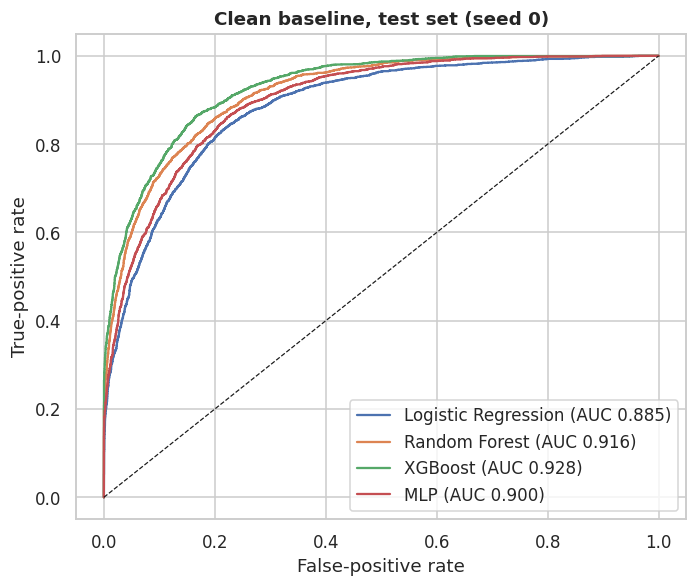

In [ ]:
# ===================================================================
# Cell 13 — Clean baseline (seed 0): four models on the clean scenario
# ===================================================================
baseline_rows, baseline_probs = [], {}
for name in CFG["MODELS"]:
    bb, met = train_and_eval(clean, name)
    p = bb.predict_proba(clean.X_test)
    assert p.shape == (len(clean.X_test), 2) and 0 <= p.min() and p.max() <= 1
    baseline_probs[name] = p[:, 1]
    baseline_rows.append(dict(model=MODEL_LABELS[name], **{k: round(v, 4) for k, v in met.items()}))
baseline = pd.DataFrame(baseline_rows).set_index("model")
display(baseline[["auc_train", "auc_val", "auc_test", "ap_train", "ap_val", "ap_test", "acc_train", "acc_val", "acc_test",
                  "f1_train", "f1_val", "f1_test", "logloss_train", "logloss_val", "logloss_test", "fit_seconds"]])

gap = (baseline["auc_train"] - baseline["auc_test"]).rename("train-test AUC gap")
print("Train-test AUC gap (flexible models overfit more than Logistic Regression):")
print(gap.round(4).to_string())
for model, a in baseline["auc_test"].items():
    print(f"[{'PASS' if AUC_RANGE[0] <= a <= AUC_RANGE[1] else 'WARN'}] clean test AUC of {model}: {a:.4f} (expected in [{AUC_RANGE[0]}, {AUC_RANGE[1]}])")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in CFG["MODELS"]:
    fpr, tpr, _ = roc_curve(clean.y_test, baseline_probs[name])
    ax.plot(fpr, tpr, label=f"{MODEL_LABELS[name]} (AUC {roc_auc_score(clean.y_test, baseline_probs[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Clean baseline, test set (seed 0)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "00_clean_baseline_roc.png"), bbox_inches="tight"); plt.show()

---
# PART C — The leakage detector
**Inputs:** processed train/test arrays, labels, feature names, optional timestamps, optional row ids (evidence only) and the model as a **black box** (`predict` / `predict_proba`).
**Output per leakage type:** score ∈ [0, 1], flag, evidence; plus verdict, estimated performance inflation and every sub-signal.
Data-level signals are computed once per scenario and cached; model-level signals are recomputed per model. A fixed surrogate probe (`HistGradientBoostingClassifier`) is used wherever the detector must re-train something.

In [ ]:
# ===================================================================
# PART C — THE LEAKAGE DETECTOR
# Detector interface:  LeakageDetector(model: BlackBox, X_train, y_train, X_test, y_test, feature_names,
#                                      ts_train=None, ts_test=None, row_id_train, row_id_test, seed, thresholds)
# Inputs are ONLY the processed arrays, labels, feature names, optional timestamps, optional row ids (used for
# evidence only) and the black-box model. A fixed surrogate probe (HistGradientBoosting) is used wherever the
# detector has to re-train something, because the evaluated model is a black box and cannot be cloned.
# -------------------------------------------------------------------
# Cell 14 — Detector utilities
# ===================================================================
def auc(y, p):
    y = np.asarray(y)
    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan")

def clip01(x):
    return np.clip(x, 0.0, 1.0)

def ap_score(y, p):
    """Average precision (area under the precision-recall curve); the metric that matters on imbalanced data."""
    y = np.asarray(y)
    return float(average_precision_score(y, p)) if len(np.unique(y)) > 1 else float("nan")

def robust_z(v):
    v = np.asarray(v, dtype=float)
    med = np.median(v)
    mad = np.median(np.abs(v - med))
    return (v - med) / (1.4826 * mad + 1e-9)

def row_hash(X, decimals=None):
    """Hash every row (rounded, bytes -> blake2b). Identical rows hash equal. Returns a list of bytes."""
    decimals = CFG["ROUND_DECIMALS"] if decimals is None else decimals
    Xr = np.ascontiguousarray(np.round(np.asarray(X, dtype=np.float64), decimals) + 0.0)   # + 0.0 turns -0.0 into 0.0
    return [hashlib.blake2b(Xr[i].tobytes(), digest_size=8).digest() for i in range(Xr.shape[0])]

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    ph = k / n
    den = 1 + z**2 / n
    centre = (ph + z**2 / (2 * n)) / den
    half = z * math.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))

def binom_excess_test(k, n, base_rate):
    """One-sided exact binomial test: is the observed rate k/n larger than base_rate?  Returns the p-value."""
    if n <= 0:
        return 1.0
    base = float(np.clip(base_rate, 1e-9, 1 - 1e-9))
    return float(stats.binomtest(int(k), int(n), p=base, alternative="greater").pvalue)

def stratified_subsample(y, n, rng):
    """Indices of a class-proportional subsample of size ~n (all indices if n >= len(y))."""
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    keep = []
    for cls in np.unique(y):
        ii = np.flatnonzero(y == cls)
        k = max(1, int(round(n * len(ii) / len(y))))
        keep.append(rng.choice(ii, size=min(k, len(ii)), replace=False))
    return np.sort(np.concatenate(keep))

def to_jsonable(o):
    """Recursively convert numpy / NaN values so that json.dumps works (NaN -> None)."""
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_jsonable(o.tolist())
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

# ---- unit tests ----------------------------------------------------------------
_A = np.array([[1.0, 2.0], [1.0, 2.0], [3.0, 4.0], [-0.0, 5.0]])
_h = row_hash(_A)
assert _h[0] == _h[1] and _h[0] != _h[2], "identical rows must hash equal"
assert row_hash(np.array([[0.0, 1.0]]))[0] == row_hash(np.array([[-0.0, 1.0]]))[0], "-0.0 and 0.0 must hash equal"
_z = robust_z(np.r_[np.random.default_rng(0).normal(0, 1, 50), 25.0])
assert _z[-1] > 10 and np.abs(_z[:-1]).max() < 5, "an outlier must get a large robust z"
lo, hi = wilson_ci(50, 100); assert 0.40 < lo < 0.5 < hi < 0.60
assert binom_excess_test(30, 100, 0.05) < 1e-6 and binom_excess_test(5, 100, 0.05) > 0.4
_ss = stratified_subsample(np.r_[np.zeros(900), np.ones(100)], 200, np.random.default_rng(0))
assert len(_ss) == 200 and abs(np.mean(np.r_[np.zeros(900), np.ones(100)][_ss]) - 0.1) < 0.02
print("PASS: utilities unit tests (hash equality, robust z of an outlier, Wilson CI, binomial test, stratified subsample).")

PASS: utilities unit tests (hash equality, robust z of an outlier, Wilson CI, binomial test, stratified subsample).


In [ ]:
# ===================================================================
# Cell 15 — Target-leakage module
#   data-level (cached): mutual information, single-feature strength, surrogate ablation
#   model-level (per model): black-box permutation importance
# NOTE: real datasets contain strong LEGITIMATE features. The ablation term and the `a - 0.85` offset exist so that
# they are not flagged; cell 24 prints the strongest legitimate features seen on clean data.
# ===================================================================
def _single_feature_strength(x, y, seed):
    """max(rank AUC in both directions, 3-fold CV AUC of a depth-4 decision tree)."""
    a = roc_auc_score(y, x)
    rank_auc = max(a, 1 - a)
    cv = StratifiedKFold(3, shuffle=True, random_state=seed)
    p = cross_val_predict(DecisionTreeClassifier(max_depth=4, random_state=seed), x.reshape(-1, 1), y,
                          cv=cv, method="predict_proba")[:, 1]
    return max(rank_auc, roc_auc_score(y, p))

def target_data_level(X_train, y_train, X_test, y_test, seed):
    rng = np.random.default_rng(seed)
    d = X_train.shape[1]
    idx = stratified_subsample(y_train, CFG["MI_SUBSAMPLE"], rng)
    Xs, ys = X_train[idx], y_train[idx]
    discrete = np.array([len(np.unique(Xs[:, j])) <= 10 for j in range(d)])
    mi = mutual_info_classif(Xs, ys, discrete_features=discrete, n_neighbors=3, random_state=seed)
    mi_z = robust_z(mi)
    top = np.argsort(-mi)[:min(CFG["TOP_K"], d)]

    a = np.full(d, np.nan)
    for j in top:                                             # mean of the strength on train and on test
        a[j] = 0.5 * (_single_feature_strength(Xs[:, j], ys, seed) + _single_feature_strength(X_test[:, j], y_test, seed))

    drop = np.zeros(d)                                        # surrogate ablation (3-fold CV AUC on train)
    cv = StratifiedKFold(3, shuffle=True, random_state=seed)
    mk = lambda: HistGradientBoostingClassifier(max_iter=100, random_state=seed)
    auc_all = cross_val_score(mk(), Xs, ys, cv=cv, scoring="roc_auc").mean()
    for j in top:
        keep = [k for k in range(d) if k != j]
        drop[j] = auc_all - cross_val_score(mk(), Xs[:, keep], ys, cv=cv, scoring="roc_auc").mean()
    return dict(mi=mi, mi_z=mi_z, top=top, a=a, drop=drop, auc_all=float(auc_all))

def target_model_level(bb, X_test, y_test, seed):
    """Black-box permutation importance (AUC loss) on <= PERM_ROWS test rows; returns each feature's positive share."""
    rng = np.random.default_rng(seed + 17)
    d = X_test.shape[1]
    idx = stratified_subsample(y_test, CFG["PERM_ROWS"], rng)
    Xp, yp = X_test[idx], y_test[idx]
    base = auc(yp, bb.predict_proba(Xp)[:, 1])
    imp = np.zeros(d)
    for j in range(d):
        losses = []
        for _ in range(CFG["PERM_REPEATS"]):
            Xq = Xp.copy()
            Xq[:, j] = rng.permutation(Xq[:, j])
            losses.append(base - auc(yp, bb.predict_proba(Xq)[:, 1]))
        imp[j] = float(np.mean(losses))
    pos = np.clip(imp, 0, None)
    share = pos / pos.sum() if pos.sum() > 0 else np.zeros(d)
    return dict(perm_importance=imp, share=share)

def target_scores(dl, ml, feature_names):
    z, a, drop, share = dl["mi_z"], np.nan_to_num(dl["a"], nan=0.0), dl["drop"], ml["share"]
    s_mi = clip01(np.log10(np.maximum(z, 1.0)) / 2.0)
    s_auc = clip01((a - 0.85) / 0.15)
    s_abl = clip01(drop / 0.05)
    s_perm = clip01((share - 0.3) / 0.5)
    f = 0.35 * s_mi + 0.30 * s_auc + 0.20 * s_abl + 0.15 * s_perm
    table = [dict(feature=feature_names[j], mi=float(dl["mi"][j]), mi_z=float(z[j]),
                  single_feature_strength=(None if np.isnan(dl["a"][j]) else float(dl["a"][j])),
                  ablation_drop=float(drop[j]), perm_share=float(share[j]),
                  s_mi=float(s_mi[j]), s_auc=float(s_auc[j]), s_abl=float(s_abl[j]), s_perm=float(s_perm[j]), f=float(f[j]))
             for j in range(len(feature_names))]
    sub = dict(mi_z_max=float(np.max(z)), single_feature_auc_max=float(np.max(a)), ablation_drop_max=float(np.max(drop)),
               perm_share_max=float(np.max(share)), s_mi_max=float(s_mi.max()), s_auc_max=float(s_auc.max()),
               s_abl_max=float(s_abl.max()), s_perm_max=float(s_perm.max()))
    return float(f.max()), f, table, sub

print("Target module ready: MI z-score + single-feature strength + ablation (data-level), permutation share (model-level).")

Target module ready: MI z-score + single-feature strength + ablation (data-level), permutation share (model-level).


In [ ]:
# ===================================================================
# Cell 16 — Contamination module
#   data-level (cached): exact-duplicate overlap + near-duplicate nearest-neighbour excess, each against a
#                        leave-one-out within-train baseline;  model-level: memorisation gap on matched test rows
# ===================================================================
def contamination_data_level(X_train, X_test, row_id_train, row_id_test, seed):
    rng = np.random.default_rng(seed + 31)
    n_tr, n_te = len(X_train), len(X_test)

    # ---- 1. exact overlap (hash of the rounded rows) -------------------------------------
    h_tr, h_te = row_hash(X_train), row_hash(X_test)
    first_pos = {}
    for i, h in enumerate(h_tr):
        first_pos.setdefault(h, i)
    exact_mask = np.array([h in first_pos for h in h_te])
    partner = np.array([first_pos.get(h, -1) for h in h_te])
    exact_rate = float(exact_mask.mean())
    # Baseline = LEAVE-ONE-OUT within train: a sampled train row is compared with ALL OTHER train rows.
    # (Holding rows out and fitting on the remainder would give the baseline a ~33% smaller reference set than the
    #  test queries have, which makes honest test rows look spuriously "closer" and inflates the clean-data score.)
    n_hold = min(CFG["NN_HOLDOUT"], n_tr // 3)
    hold = rng.choice(n_tr, size=n_hold, replace=False)
    h_count = {}
    for h in h_tr:
        h_count[h] = h_count.get(h, 0) + 1
    b_exact = float(np.mean([h_count[h_tr[i]] > 1 for i in hold]))      # does the row have an identical twin elsewhere in train?
    excess_exact = max(0.0, exact_rate - b_exact)
    p_exact = binom_excess_test(int(exact_mask.sum()), n_te, b_exact)
    if p_exact >= 0.01:
        excess_exact = 0.0

    # ---- 2. near-duplicates (kd-tree nearest neighbour on the FULL train) -------------------
    nq = min(CFG["NN_QUERY"], n_te)
    q_idx = rng.choice(n_te, size=nq, replace=False)
    nn_full = NearestNeighbors(n_neighbors=1, algorithm="kd_tree").fit(X_train)
    d_test, nn_idx = nn_full.kneighbors(X_test[q_idx])
    d_test, nn_idx = d_test[:, 0], nn_idx[:, 0]
    d_base = nn_full.kneighbors(X_train[hold], n_neighbors=2)[0][:, 1]       # 2nd neighbour = nearest OTHER train row
    eps = max(float(np.quantile(d_base, 0.05)), 1e-6)
    o = float(np.mean(d_test <= eps))
    b = float(np.mean(d_base <= eps))
    excess_nn = max(0.0, (o - b) / (1 - b)) if b < 1 else 0.0
    p_nn = binom_excess_test(int(round(o * nq)), nq, b)
    if p_nn >= 0.01:
        excess_nn = 0.0

    s_dup = float(clip01(excess_exact / 0.02))
    s_nn = float(clip01(excess_nn / 0.05))

    # ---- evidence + the set of matched test rows (only if a signal is significant) ----------
    sig_any = excess_exact > 0 or excess_nn > 0
    matched = np.zeros(n_te, dtype=bool)
    if excess_exact > 0:
        matched |= exact_mask
    if excess_nn > 0:
        matched[q_idx[d_test <= eps]] = True
    exact_rows = np.flatnonzero(exact_mask) if sig_any else np.array([], dtype=int)
    near_sel = d_test <= eps
    pos_q = {int(r): i for i, r in enumerate(q_idx)}
    near_rows = np.array([r for r in q_idx[near_sel] if not exact_mask[r]], dtype=int) if excess_nn > 0 else np.array([], dtype=int)
    near_partner = np.array([nn_idx[pos_q[int(r)]] for r in near_rows], dtype=int) if len(near_rows) else np.array([], dtype=int)
    matched_train_pos = np.unique(np.concatenate([partner[exact_rows] if len(exact_rows) else np.array([], dtype=int),
                                                  near_partner])).astype(int)    # train rows that are partners of a matched test row
    rid_tr, rid_te = np.asarray(row_id_train), np.asarray(row_id_test)
    evidence = dict(
        n_exact=int(len(exact_rows)), n_near=int(len(near_rows)),
        dup_test_row_ids=rid_te[np.concatenate([exact_rows, near_rows]).astype(int)].tolist(),
        dup_test_row_ids_exact=rid_te[exact_rows].tolist(),
        dup_test_row_ids_near=rid_te[near_rows].tolist(),
        dup_train_row_ids=np.concatenate([rid_tr[partner[exact_rows]] if len(exact_rows) else np.array([], int),
                                          rid_tr[near_partner] if len(near_partner) else np.array([], int)]).astype(int).tolist(),
        near_eps=eps)
    return dict(exact_rate=exact_rate, base_exact=b_exact, excess_exact=excess_exact, p_exact=p_exact,
                nn_eps=eps, nn_obs=o, nn_base=b, excess_nn=excess_nn, p_nn=p_nn,
                s_dup=s_dup, s_nn=s_nn, matched_mask=matched, evidence=evidence,
                exact_mask=exact_mask, exact_partner=partner, matched_train_pos=matched_train_pos)

def contamination_model_level(bb, X_test, y_test, dl, p_test=None):
    """Memorisation gap: black-box AUC on matched test rows minus AUC on unmatched rows (>= 30 matched rows needed)."""
    m = dl["matched_mask"]
    gap = float("nan")
    if m.sum() >= 30 and (~m).sum() >= 30 and len(np.unique(y_test[m])) > 1 and len(np.unique(y_test[~m])) > 1:
        p = bb.predict_proba(X_test)[:, 1] if p_test is None else p_test
        gap = auc(y_test[m], p[m]) - auc(y_test[~m], p[~m])
    s_mem = float(clip01(gap / 0.2)) if np.isfinite(gap) else 0.0
    return dict(mem_gap=gap, s_mem=s_mem, n_matched=int(m.sum()))

def contamination_score(dl, ml):
    return float(0.8 * max(dl["s_dup"], dl["s_nn"]) + 0.2 * ml["s_mem"])

print("Contamination module ready: exact hash overlap + kd-tree near-duplicate excess (both vs. a within-train baseline).")

Contamination module ready: exact hash overlap + kd-tree near-duplicate excess (both vs. a within-train baseline).


In [ ]:
# ===================================================================
# Cell 17 — Temporal-leakage module
# Abstains (score = NaN) when no timestamps are given. The logic is self-tested on a SYNTHETIC dataset below
# (not part of the reported results). De-duplication first: train rows matched as duplicates in cell 16 are ignored.
# ===================================================================
def _ts_to_float(ts):
    ts = pd.Series(ts)
    if np.issubdtype(ts.dtype, np.datetime64):
        return ts.astype("int64").to_numpy(dtype=float)
    return ts.to_numpy(dtype=float)

def temporal_module(X_train, y_train, X_test, y_test, ts_train=None, ts_test=None, exclude_train_pos=None, seed=0):
    if ts_train is None or ts_test is None:
        return dict(score=float("nan"), evidence={"abstained": "no timestamp"}, signals={})
    t_tr, t_te = _ts_to_float(ts_train), _ts_to_float(ts_test)
    keep = np.ones(len(t_tr), dtype=bool)
    if exclude_train_pos is not None and len(exclude_train_pos):       # de-duplicate first (cell 16 matches)
        keep[np.asarray(exclude_train_pos, dtype=int)] = False
    t_lo, t_hi = float(np.min(t_te)), float(np.max(t_te))
    overlap_frac = float(np.mean(t_tr[keep] >= t_lo))                  # train rows at/after the start of the test period
    future_frac = float(np.mean(t_tr[keep] > t_hi))                    # train rows strictly after the test period
    suggested_cut = t_lo
    # time-ordered re-split with the surrogate: same sizes, but strictly chronological
    mk = lambda: HistGradientBoostingClassifier(max_iter=100, random_state=seed)
    a_given = auc(y_test, mk().fit(X_train[keep], y_train[keep]).predict_proba(X_test)[:, 1])
    Xa, ya, ta = np.vstack([X_train, X_test]), np.r_[y_train, y_test], np.r_[t_tr, t_te]
    order = np.argsort(ta, kind="stable")
    n_tr = len(X_train)
    tr_i, te_i = order[:n_tr], order[n_tr:]
    a_chrono = auc(ya[te_i], mk().fit(Xa[tr_i], ya[tr_i]).predict_proba(Xa[te_i])[:, 1])
    delta = a_given - a_chrono
    score = 0.7 * float(clip01(overlap_frac / 0.05)) + 0.3 * float(clip01(delta / 0.05))
    return dict(score=score,
                evidence=dict(overlap_frac=overlap_frac, future_frac=future_frac, suggested_cut=suggested_cut,
                              auc_given_split=a_given, auc_chronological=a_chrono, delta=delta),
                signals=dict(overlap_frac=overlap_frac, future_frac=future_frac, temporal_delta=delta))

# ---- SELF-TEST on synthetic timestamps (verifies the module for datasets that DO have time) --------------
def _synthetic_time_data(n=6000, seed=0):
    r = np.random.default_rng(seed)
    t = np.sort(r.uniform(0, 1, n))
    X = r.normal(size=(n, 4))
    w = np.stack([np.cos(3 * t), np.sin(3 * t), 0.5 * np.ones(n), -0.5 * np.ones(n)], axis=1)   # concept drift over time
    y = ((X * w).sum(1) + 0.3 * r.normal(size=n) > 0).astype(int)
    return X, y, t

_X, _y, _t = _synthetic_time_data()
_past = np.flatnonzero(_t < 0.6); _test = np.flatnonzero((_t >= 0.6) & (_t < 0.8)); _future = np.flatnonzero(_t >= 0.8)
_r = np.random.default_rng(1)
ok_split = _past                                                                # correct chronological split
leaky = np.r_[_past, _r.choice(_future, size=int(0.25 * len(_past)), replace=False)]   # ~20% of train after the test period
res_ok = temporal_module(_X[ok_split], _y[ok_split], _X[_test], _y[_test], _t[ok_split], _t[_test])
res_leak = temporal_module(_X[leaky], _y[leaky], _X[_test], _y[_test], _t[leaky], _t[_test])
res_none = temporal_module(_X[ok_split], _y[ok_split], _X[_test], _y[_test])
print(f"correct chronological split : score = {res_ok['score']:.3f}  overlap_frac = {res_ok['evidence']['overlap_frac']:.3f}  -> {'PASS (no flag)' if res_ok['score'] < 0.5 else 'FAIL'}")
print(f"20% of train after test     : score = {res_leak['score']:.3f}  overlap_frac = {res_leak['evidence']['overlap_frac']:.3f}  -> {'PASS (flag)' if res_leak['score'] >= 0.5 else 'FAIL'}")
print(f"no timestamp given           : score = {res_none['score']}  evidence = {res_none['evidence']}  -> {'PASS (abstains)' if np.isnan(res_none['score']) else 'FAIL'}")
assert res_ok["score"] < 0.5 <= res_leak["score"] and np.isnan(res_none["score"]), "temporal module self-test failed"
del _X, _y, _t, _past, _test, _future, _r, ok_split, leaky

correct chronological split : score = 0.000  overlap_frac = 0.000  -> PASS (no flag)
20% of train after test     : score = 1.000  overlap_frac = 0.200  -> PASS (flag)
no timestamp given           : score = nan  evidence = {'abstained': 'no timestamp'}  -> PASS (abstains)


In [ ]:
# ===================================================================
# Cell 18 — Preprocessing-leakage module (works on the processed arrays only, exact fingerprints)
#   A column is "train-consistent" if its statistics look like they were fitted on train only, and
#   "pooled-consistent" if they look like they were fitted on train+test. A score is the share of
#   pooled-consistent columns among all columns that are consistent with ANY story (columns that fit neither
#   story, e.g. a naturally capped column, say nothing about the fit scope and are ignored).
# ===================================================================
def _ratio(n_pool, n_train):
    return float(n_pool / (n_pool + n_train)) if (n_pool + n_train) > 0 else 0.0

def preprocessing_module(X_train, X_test, feature_names):
    tol = CFG["FP_TOL"]
    Xp = np.vstack([X_train, X_test])
    d = X_train.shape[1]
    nuniq = np.array([len(np.unique(Xp[:, j])) for j in range(d)])
    ev = dict(scaler={}, imputation={}, encoding={})

    # 1. scaler fingerprint (> 20 distinct values; frequency-encoded columns have <= 10)
    n_pool = n_train = 0
    for j in np.flatnonzero(nuniq > 20):
        tr, po = X_train[:, j], Xp[:, j]
        std_tr = abs(tr.mean()) < tol and abs(tr.std() - 1) < tol
        mm_tr = abs(tr.min()) < tol and abs(tr.max() - 1) < tol
        std_po = abs(po.mean()) < tol and abs(po.std() - 1) < tol
        mm_po = abs(po.min()) < tol and abs(po.max() - 1) < tol
        train_cons = std_tr or mm_tr
        pooled_cons = (std_po or mm_po) and not train_cons
        n_train += int(train_cons); n_pool += int(pooled_cons)
        ev["scaler"][feature_names[j]] = ("train-consistent" if train_cons else "POOLED-consistent" if pooled_cons else "neither")
    s_scale = _ratio(n_pool, n_train)

    # 2. imputation fingerprint: a spike (modal value with frequency in [1%, 80%]) equal to a column mean
    n_pool = n_train = 0
    for j in range(d):
        vals, cnt = np.unique(X_train[:, j], return_counts=True)
        freq = cnt.max() / len(X_train)
        if not (0.01 <= freq <= 0.80):
            continue
        v = vals[cnt.argmax()]
        m_tr = X_train[X_train[:, j] != v, j].mean()
        m_po = Xp[Xp[:, j] != v, j].mean()
        train_cons = abs(v - m_tr) < tol
        pooled_cons = abs(v - m_po) < tol and abs(v - m_tr) > 10 * tol
        n_train += int(train_cons); n_pool += int(pooled_cons)
        ev["imputation"][feature_names[j]] = dict(spike_share=float(freq),
            verdict=("train-consistent" if train_cons else "POOLED-consistent" if pooled_cons else "neither"))
    s_imp = _ratio(n_pool, n_train)

    # 3. frequency-encoding fingerprint: unscaled columns with <= 10 distinct values in (0, 1]
    n_pool = n_train = 0
    for j in np.flatnonzero(nuniq <= 10):
        po_vals = np.unique(Xp[:, j])
        vals = po_vals[po_vals != 0.0]
        if len(vals) == 0 or vals.min() <= 0 or vals.max() > 1:
            continue
        tr_ok = all(abs(v - np.mean(X_train[:, j] == v)) < tol for v in vals)
        po_ok = all(abs(v - np.mean(Xp[:, j] == v)) < tol for v in vals)
        train_cons, pooled_cons = tr_ok, po_ok and not tr_ok
        n_train += int(train_cons); n_pool += int(pooled_cons)
        ev["encoding"][feature_names[j]] = ("train-consistent" if train_cons else "POOLED-consistent" if pooled_cons else "neither")
    s_enc = _ratio(n_pool, n_train)

    score = float(max(s_scale, s_imp, s_enc))
    if not (ev["scaler"] or ev["imputation"] or ev["encoding"]):
        ev["note"] = "no fingerprintable column"
    return dict(score=score, s_scale=s_scale, s_imp=s_imp, s_enc=s_enc, evidence=ev)

# ---- checks on the real scenarios (seed 0): clean -> 0, prep_L -> scale, prep_M adds imputation, prep_H adds encoding
_exp = {"clean": (0, 0, 0), "prep_L": (1, 0, 0), "prep_M": (1, 1, 0)}
if HAS_CATEGORICAL:
    _exp["prep_H"] = (1, 1, 1)
for _sid, (e_sc, e_im, e_en) in _exp.items():
    _s = build_scenario(0, _sid)
    _r = preprocessing_module(_s.X_train, _s.X_test, _s.feature_names)
    _ok = abs(_r["s_scale"] - e_sc) < 1e-9 and abs(_r["s_imp"] - e_im) < 1e-9 and abs(_r["s_enc"] - e_en) < 1e-9
    print(f"[{'PASS' if _ok else 'FAIL'}] {_sid:7s} s_scale={_r['s_scale']:.2f} s_imp={_r['s_imp']:.2f} s_enc={_r['s_enc']:.2f}  (expected {e_sc},{e_im},{e_en})")
    assert _ok, f"preprocessing fingerprint check failed for {_sid}"
del _s, _r

[PASS] clean   s_scale=0.00 s_imp=0.00 s_enc=0.00  (expected 0,0,0)
[PASS] prep_L  s_scale=1.00 s_imp=0.00 s_enc=0.00  (expected 1,0,0)
[PASS] prep_M  s_scale=1.00 s_imp=1.00 s_enc=0.00  (expected 1,1,0)
[PASS] prep_H  s_scale=1.00 s_imp=1.00 s_enc=1.00  (expected 1,1,1)


In [ ]:
# ===================================================================
# Cell 19 — Adversarial validation (supporting signal only: weight 0 in every score)
# ===================================================================
TIME_PROXY_TOKENS = {"time", "date", "year", "month", "week", "day", "timestamp", "period"}

def adversarial_validation(X_train, X_test, feature_names, seed):
    """Train rows = 0, test rows = 1; 3-fold out-of-fold AUC of a small random forest (~0.5 for a random split)."""
    rng = np.random.default_rng(seed + 53)
    drop = [j for j, nm in enumerate(feature_names) if set(str(nm).lower().split("_")) & TIME_PROXY_TOKENS]
    keep = [j for j in range(X_train.shape[1]) if j not in drop]      # no time-proxy columns here -> nothing removed
    n_tot = len(X_train) + len(X_test)
    frac = min(1.0, CFG["ADV_SUBSAMPLE"] / n_tot)
    i_tr = rng.choice(len(X_train), size=int(len(X_train) * frac), replace=False)
    i_te = rng.choice(len(X_test), size=int(len(X_test) * frac), replace=False)
    X = np.vstack([X_train[i_tr][:, keep], X_test[i_te][:, keep]])
    y = np.r_[np.zeros(len(i_tr)), np.ones(len(i_te))].astype(int)
    rf = RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=seed)
    oof = cross_val_predict(rf, X, y, cv=StratifiedKFold(3, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    adv_auc = float(roc_auc_score(y, oof))
    imp = rf.fit(X, y).feature_importances_
    top = np.argsort(-imp)[:5]
    return dict(adv_auc=adv_auc, top_features=[(feature_names[keep[j]], float(imp[j])) for j in top],
                removed_time_proxies=[feature_names[j] for j in drop])

_s = build_scenario(0, "clean")
_adv = adversarial_validation(_s.X_train, _s.X_test, _s.feature_names, 0)
print(f"clean, seed 0: adversarial AUC = {_adv['adv_auc']:.3f} (about 0.5 expected for a random split) | removed time proxies: {_adv['removed_time_proxies'] or 'none'}")
print("top-5 importances:", [(n, round(v, 3)) for n, v in _adv["top_features"]])
del _s, _adv

clean, seed 0: adversarial AUC = 0.502 (about 0.5 expected for a random split) | removed time proxies: ['hours_per_week']
top-5 importances: [('fnlwgt', 0.233), ('age', 0.171), ('education_num', 0.115), ('occupation_freq', 0.089), ('native_country_freq', 0.061)]


In [ ]:
# ===================================================================
# Cell 20 — Model-level signals (stored in `signals`, evaluated in cell 29, never used alone to flag)
# ===================================================================
def model_level_signals(bb, X_train, y_train, X_test, y_test, p_test=None):
    p_tr = bb.predict_proba(X_train)
    p_te = bb.predict_proba(X_test) if p_test is None else np.column_stack([1 - p_test, p_test])
    return dict(gap_auc=auc(y_train, p_tr[:, 1]) - auc(y_test, p_te[:, 1]),
                gap_conf=float(p_tr.max(axis=1).mean() - p_te.max(axis=1).mean()),
                auc_train_bb=auc(y_train, p_tr[:, 1]), auc_test_bb=auc(y_test, p_te[:, 1]))

print("Model-level signals: gap_auc = AUC_train - AUC_test and gap_conf = mean(max proba) train - test.")

Model-level signals: gap_auc = AUC_train - AUC_test and gap_conf = mean(max proba) train - test.


In [ ]:
# ===================================================================
# Cell 21 — Remediation and performance-inflation estimate
#   AUC_given     = black-box AUC on the test set as given   (the same is done for average precision, AP)
#   target        : replace each flagged suspect column of the test matrix by a within-test permutation of itself
#   contamination : drop the test rows matched as duplicates
#   temporal      : surrogate AUC on the given split minus surrogate AUC on a strictly chronological re-split
#   est = metric_given - metric_after_remediation   (clipped at 0)
#   preprocessing : not estimated (documented blind spot, contribution 0)
# ===================================================================
def estimate_inflation(bb, X_test, y_test, p_given, flags, suspect_idx, matched_mask, seed, temporal_delta=float("nan")):
    rng = np.random.default_rng(seed + 71)
    auc_given, ap_given = auc(y_test, p_given), ap_score(y_test, p_given)
    est = {"target": 0.0, "contamination": 0.0, "temporal": (0.0 if np.isfinite(temporal_delta) else None), "preprocessing": 0.0}
    est_ap = {"target": 0.0, "contamination": 0.0}

    def _permute(Xm):
        Xm = Xm.copy()
        for j in suspect_idx:
            Xm[:, j] = rng.permutation(Xm[:, j])
        return Xm

    do_t = bool(flags["target"]) and len(suspect_idx) > 0
    do_c = bool(flags["contamination"]) and int(matched_mask.sum()) > 0
    keep = ~matched_mask if do_c else np.ones(len(y_test), dtype=bool)
    valid = lambda m: len(np.unique(y_test[m])) > 1
    if do_t:
        p_t = bb.predict_proba(_permute(X_test))[:, 1]
        est["target"] = max(0.0, auc_given - auc(y_test, p_t))
        est_ap["target"] = max(0.0, ap_given - ap_score(y_test, p_t))
    if do_c and valid(keep):
        est["contamination"] = max(0.0, auc_given - auc(y_test[keep], p_given[keep]))
        est_ap["contamination"] = max(0.0, ap_given - ap_score(y_test[keep], p_given[keep]))
    total, total_ap = 0.0, 0.0
    if (do_t or do_c) and valid(keep):                      # both remediations applied jointly (no double counting)
        Xr = _permute(X_test[keep]) if do_t else X_test[keep]
        p_r = bb.predict_proba(Xr)[:, 1]
        total = max(0.0, auc_given - auc(y_test[keep], p_r))
        total_ap = max(0.0, ap_given - ap_score(y_test[keep], p_r))
    if flags.get("temporal") and np.isfinite(temporal_delta):
        est["temporal"] = max(0.0, float(temporal_delta))
        total += est["temporal"]
    return dict(auc_given=auc_given, ap_given=ap_given, est_inflation=float(total), est_inflation_ap=float(total_ap),
                est_by_type=est, est_by_type_ap=est_ap)

print("Inflation estimator ready (target: permute suspects; contamination: drop matched rows; temporal: chronological re-split; preprocessing: 0).")


Inflation estimator ready (target: permute suspects; contamination: drop matched rows; temporal: chronological re-split; preprocessing: 0).


In [ ]:
# ===================================================================
# Cell 22 — Aggregator: LeakageDetector (data-level cache per scenario, model-level per model)
# ===================================================================
def compute_data_level(X_train, y_train, X_test, y_test, feature_names, ts_train=None, ts_test=None,
                       row_id_train=None, row_id_test=None, seed=0):
    """All signals that depend on the DATA only. Computed once per scenario and reused for every model."""
    row_id_train = np.arange(len(X_train)) if row_id_train is None else row_id_train
    row_id_test = np.arange(len(X_test)) + 10**9 if row_id_test is None else row_id_test
    c, tm = {}, {}
    t = time.time(); c["contam"] = contamination_data_level(X_train, X_test, row_id_train, row_id_test, seed); tm["contamination"] = time.time() - t
    t = time.time(); c["target"] = target_data_level(X_train, y_train, X_test, y_test, seed); tm["target"] = time.time() - t
    t = time.time(); c["prep"] = preprocessing_module(X_train, X_test, feature_names); tm["preprocessing"] = time.time() - t
    t = time.time(); c["adv"] = adversarial_validation(X_train, X_test, feature_names, seed); tm["adversarial"] = time.time() - t
    t = time.time()
    excl = c["contam"]["matched_train_pos"]
    c["temporal"] = temporal_module(X_train, y_train, X_test, y_test, ts_train, ts_test, exclude_train_pos=excl, seed=seed)
    tm["temporal"] = time.time() - t
    c["timings"] = tm
    return c

class LeakageDetector:
    def __init__(self, model, X_train, y_train, X_test, y_test, feature_names, ts_train=None, ts_test=None,
                 row_id_train=None, row_id_test=None, seed=0, thresholds=None, cache=None):
        self.model = model if isinstance(model, BlackBox) else BlackBox(model)
        self.X_train, self.y_train, self.X_test, self.y_test = X_train, y_train, X_test, y_test
        self.names = list(feature_names)
        self.seed = seed
        self.thr = dict(CFG["THRESH"] if thresholds is None else thresholds)
        self.row_id_train, self.row_id_test = row_id_train, row_id_test
        self.cache = cache if cache is not None else compute_data_level(
            X_train, y_train, X_test, y_test, feature_names, ts_train, ts_test, row_id_train, row_id_test, seed)

    def run(self, model=None):
        bb = self.model if model is None else (model if isinstance(model, BlackBox) else BlackBox(model))
        C, tm = self.cache, {}
        t0 = time.time()
        p_test = bb.predict_proba(self.X_test)[:, 1]

        t = time.time(); ml_t = target_model_level(bb, self.X_test, self.y_test, self.seed); tm["target_model"] = time.time() - t
        sc_t, f_t, table, sub_t = target_scores(C["target"], ml_t, self.names)
        t = time.time(); ml_c = contamination_model_level(bb, self.X_test, self.y_test, C["contam"], p_test); tm["contamination_model"] = time.time() - t
        sc_c = contamination_score(C["contam"], ml_c)
        sc_p = C["prep"]["score"]
        tmp = C["temporal"]
        t = time.time(); gaps = model_level_signals(bb, self.X_train, self.y_train, self.X_test, self.y_test, p_test); tm["gaps"] = time.time() - t

        scores = dict(target=sc_t, contamination=sc_c, temporal=tmp["score"], preprocessing=sc_p)
        flags = {k: bool(np.isfinite(v) and v >= self.thr[k]) for k, v in scores.items()}       # temporal: NaN -> False
        order = np.argsort(-f_t)
        suspect_idx = [int(j) for j in order if f_t[j] >= self.thr["target"]]
        t = time.time()
        infl = estimate_inflation(bb, self.X_test, self.y_test, p_test, flags, suspect_idx, C["contam"]["matched_mask"], self.seed,
                                  temporal_delta=tmp["evidence"].get("delta", float("nan")))
        tm["inflation"] = time.time() - t

        cd, cev = C["contam"], C["contam"]["evidence"]
        signals = dict(sub_t, exact_excess=cd["excess_exact"], nn_excess=cd["excess_nn"], s_dup=cd["s_dup"], s_nn=cd["s_nn"],
                       mem_gap=ml_c["mem_gap"], s_mem=ml_c["s_mem"], n_matched=ml_c["n_matched"], near_eps=cd["nn_eps"],
                       base_exact=cd["base_exact"], base_nn=cd["nn_base"],
                       s_scale=C["prep"]["s_scale"], s_imp=C["prep"]["s_imp"], s_enc=C["prep"]["s_enc"],
                       adv_auc=C["adv"]["adv_auc"], gap_auc=gaps["gap_auc"], gap_conf=gaps["gap_conf"],
                       auc_given=infl["auc_given"], ap_given=infl["ap_given"], est_inflation_ap=infl["est_inflation_ap"],
                       overlap_frac=tmp["signals"].get("overlap_frac", float("nan")),
                       temporal_delta=tmp["signals"].get("temporal_delta", float("nan")), n_blackbox_calls=bb.n_calls)
        report = {
            "target": dict(score=sc_t, flag=flags["target"], evidence=dict(
                suspect_features=[self.names[j] for j in suspect_idx],
                ranked_features=[self.names[j] for j in order[:5]],
                per_feature=table)),
            "contamination": dict(score=sc_c, flag=flags["contamination"], evidence=cev),
            "temporal": dict(score=tmp["score"], flag=flags["temporal"], evidence=tmp["evidence"]),
            "preprocessing": dict(score=sc_p, flag=flags["preprocessing"], evidence=C["prep"]["evidence"]),
            "verdict": "leaky" if any(flags.values()) else "clean",
            "est_inflation": infl["est_inflation"],
            "est_inflation_by_type": infl["est_by_type"],
            "est_inflation_by_type_ap": infl["est_by_type_ap"],
            "est_inflation_ap": infl["est_inflation_ap"],
            "signals": signals,
            "adversarial_top_features": C["adv"]["top_features"],
            "timings": dict(C["timings"], **tm, total_model_level=time.time() - t0),
            "_suspect_idx": suspect_idx,
        }
        # contract: all keys present, no NaN score except the temporal abstention
        assert all(k in report for k in ("target", "contamination", "temporal", "preprocessing", "verdict", "est_inflation", "est_inflation_by_type", "signals"))
        assert all(np.isfinite(report[k]["score"]) for k in CFG["EVALUATED_TYPES"]), "NaN score"
        return report

def detector_for(scn, bb, cache=None, thresholds=None):
    """Build a detector from a ScenarioData: ONLY arrays, labels, names, timestamps (None), row ids and the black box."""
    return LeakageDetector(bb, scn.X_train, scn.y_train, scn.X_test, scn.y_test, scn.feature_names,
                           scn.ts_train, scn.ts_test, scn.row_id_train, scn.row_id_test, scn.seed, thresholds, cache)

print("LeakageDetector ready. Data-level signals are cached per scenario; model-level signals are recomputed per model.")

LeakageDetector ready. Data-level signals are cached per scenario; model-level signals are recomputed per model.


In [ ]:
# ===================================================================
# Cell 23 — Detector smoke test (seed 0, XGBoost)
# ===================================================================
smoke_ids = [s for s in ("clean", "target_H", "contam_H", "temp_H", "prep_H" if HAS_CATEGORICAL else "prep_M") if s in ACTIVE_SCENARIOS]
smoke_rows, smoke_reports = [], {}
for sid in smoke_ids:
    scn = build_scenario(0, sid)
    bb, met = train_and_eval(scn, "xgb")
    t = time.time(); det = detector_for(scn, bb); rep = det.run(); dt = time.time() - t
    smoke_reports[sid] = rep
    smoke_rows.append(dict(scenario=sid, test_auc=round(met["auc_test"], 4), test_ap=round(met["ap_test"], 4),
                           score_target=round(rep["target"]["score"], 3), score_contam=round(rep["contamination"]["score"], 3),
                           score_prep=round(rep["preprocessing"]["score"], 3),
                           score_temporal=("abstained" if np.isnan(rep["temporal"]["score"]) else round(rep["temporal"]["score"], 3)),
                           flags=[k for k in CFG["EVALUATED_TYPES"] if rep[k]["flag"]], verdict=rep["verdict"],
                           est_inflation=round(rep["est_inflation"], 4), seconds=round(dt, 1)))
display(pd.DataFrame(smoke_rows))
for sid, rep in smoke_reports.items():
    print(f"{sid:9s} suspects: {rep['target']['evidence']['suspect_features'] or '-'} | top-5 by f: {rep['target']['evidence']['ranked_features']}"
          f" | contamination: {rep['contamination']['evidence']['n_exact']} exact + {rep['contamination']['evidence']['n_near']} near")

expected = {"clean": None, "target_H": "target", "contam_H": "contamination", "temp_H": "temporal", "prep_H": "preprocessing", "prep_M": "preprocessing"}
for sid, rep in smoke_reports.items():
    sc = {k: rep[k]["score"] for k in CFG["EVALUATED_TYPES"]}
    exp = expected[sid]
    if exp is None:
        print(f"[{'PASS' if rep['verdict'] == 'clean' else 'WARN'}] clean: no flag expected -> verdict = {rep['verdict']}")
    else:
        top = max(sc, key=sc.get)
        print(f"[{'PASS' if top == exp and rep[exp]['flag'] else 'WARN'}] {sid}: injected type '{exp}' should score highest and be flagged -> top = {top}, flagged = {rep[exp]['flag']}")
if not TS_COL:
    print(f"[{'PASS' if all(np.isnan(r['temporal']['score']) and r['temporal']['evidence'].get('abstained') for r in smoke_reports.values()) else 'FAIL'}] temporal module abstains ('no timestamp')")
print("Soft checks only: thresholds are calibrated next (cell 24).")


,scenario,test_auc,test_ap,score_target,score_contam,score_prep,score_temporal,flags,verdict,est_inflation,seconds
0,clean,0.9284,0.8299,0.116,0.000,0.0,abstained,[],clean,0.0000,18.2
1,target_H,1.0000,1.0000,0.830,0.000,0.0,abstained,[target],leaky,0.2356,27.0
2,contam_H,0.9289,0.8301,0.092,0.803,0.0,abstained,[contamination],leaky,0.0005,27.4
3,prep_H,0.9286,0.8303,0.116,0.000,1.0,abstained,[preprocessing],leaky,0.0000,17.4


clean     suspects: - | top-5 by f: ['capital_gain', 'relationship_freq', 'marital_status_freq', 'education_num', 'occupation_freq'] | contamination: 0 exact + 0 near
target_H  suspects: ['leak_feat'] | top-5 by f: ['leak_feat', 'relationship_freq', 'marital_status_freq', 'education_num', 'capital_gain'] | contamination: 0 exact + 0 near
contam_H  suspects: - | top-5 by f: ['capital_gain', 'marital_status_freq', 'relationship_freq', 'age', 'occupation_freq'] | contamination: 983 exact + 534 near
prep_H    suspects: - | top-5 by f: ['capital_gain', 'relationship_freq', 'marital_status_freq', 'education_num', 'occupation_freq'] | contamination: 0 exact + 0 near
[PASS] clean: no flag expected -> verdict = clean
[PASS] target_H: injected type 'target' should score highest and be flagged -> top = target, flagged = True
[PASS] contam_H: injected type 'contamination' should score highest and be flagged -> top = contamination, flagged = True
[PASS] prep_H: injected type 'preprocessing' should 

In [ ]:
# ===================================================================
# Cell 24 — Threshold calibration on CAL_SEEDS only, then FROZEN
#   For each evaluated type: if q95 of the CLEAN scores >= THRESH[type], set THRESH[type] = min(0.9, q95 + 0.05).
#   Thresholds are never lowered. target_M, contam_M, prep_M are run for context only (printed, not tuned).
# ===================================================================
CAL_FILE = os.path.join(RESULTS_DIR, "thresholds.json")
CAL_SIGNATURE = dict(quick=CFG["QUICK_MODE"], cal_seeds=CFG["CAL_SEEDS"], schema=SCHEMA, models=CFG["MODELS"],
                     n_rows=int(len(data)), neg_subsample=CFG.get("NEG_SUBSAMPLE"), contam_stratify=CFG["CONTAM_STRATIFY"])
CONTEXT_SCENARIOS = [s for s in ("target_M", "contam_M", "temp_M", "prep_M") if s in ACTIVE_SCENARIOS]

loaded = None
if CFG["RESUME"] and os.path.exists(CAL_FILE):
    with open(CAL_FILE) as fh:
        saved = json.load(fh)
    if saved.get("signature") == CAL_SIGNATURE:
        loaded = saved
        print("Re-using calibrated thresholds from", CAL_FILE, "(same configuration).")

if loaded is not None:
    THRESH_FROZEN = {k: float(v) for k, v in loaded["thresholds"].items()}
    cal_df = pd.DataFrame(loaded.get("calibration_scores", []))
else:
    cal_records, clean_f = [], {}
    bar = tqdm(total=len(CFG["CAL_SEEDS"]) * (1 + len(CONTEXT_SCENARIOS)), desc="calibration")
    for seed in CFG["CAL_SEEDS"]:
        for sid in ["clean"] + CONTEXT_SCENARIOS:
            scn = build_scenario(seed, sid)
            cache = compute_data_level(scn.X_train, scn.y_train, scn.X_test, scn.y_test, scn.feature_names,
                                       scn.ts_train, scn.ts_test, scn.row_id_train, scn.row_id_test, seed)
            for name in CFG["MODELS"]:
                bb, met = train_and_eval(scn, name)
                rep = detector_for(scn, bb, cache=cache).run()
                cal_records.append(dict(seed=seed, scenario=sid, model=name, auc_test=met["auc_test"],
                                        **{f"score_{k}": rep[k]["score"] for k in CFG["EVALUATED_TYPES"]}))
                if sid == "clean":
                    for r_ in rep["target"]["evidence"]["per_feature"]:
                        clean_f.setdefault(r_["feature"], []).append(r_["f"])
            bar.update(1); gc.collect()
    bar.close()
    cal_df = pd.DataFrame(cal_records)

    THRESH_FROZEN = dict(CFG["THRESH"])
    clean_cal = cal_df[cal_df.scenario == "clean"]
    print("\nCLEAN scores on calibration seeds (q95 decides the threshold):")
    for t in CFG["EVALUATED_TYPES"]:
        q95 = float(np.quantile(clean_cal[f"score_{t}"], 0.95))
        old = THRESH_FROZEN[t]
        if q95 >= old:
            THRESH_FROZEN[t] = float(min(0.9, q95 + 0.05))
        print(f"  {t:14s} clean: max={clean_cal[f'score_{t}'].max():.3f}  q95={q95:.3f}  threshold {old:.2f} -> {THRESH_FROZEN[t]:.2f}")
    # every feature of the clean scenario is legitimate: report the strongest ones against the frozen threshold
    top_legit = sorted(((float(np.max(v)), k) for k, v in clean_f.items()), reverse=True)[:3]
    if top_legit:
        ok = top_legit[0][0] < THRESH_FROZEN["target"]
        print(f"\n[{'PASS' if ok else 'FAIL'}] strongest LEGITIMATE features on clean data: "
              + ", ".join(f"{k} (max f={v:.3f})" for v, k in top_legit)
              + f"  vs frozen target threshold {THRESH_FROZEN['target']:.2f}")

    with open(CAL_FILE, "w") as fh:
        json.dump(dict(signature=CAL_SIGNATURE, thresholds=THRESH_FROZEN, calibration_scores=to_jsonable(cal_records)), fh, indent=2)

CFG["THRESH"] = dict(THRESH_FROZEN)
print("\nFROZEN thresholds:", THRESH_FROZEN, "-> saved to", CAL_FILE)
if len(cal_df):
    ctx = cal_df.groupby(["scenario"])[[f"score_{t}" for t in CFG["EVALUATED_TYPES"]]].mean().round(3)
    print("\nMean detector scores on calibration seeds (context, NOT used for tuning):")
    display(ctx)

calibration:   0%|          | 0/20 [00:00<?, ?it/s]


CLEAN scores on calibration seeds (q95 decides the threshold):
  target         clean: max=0.124  q95=0.124  threshold 0.50 -> 0.50
  contamination  clean: max=0.035  q95=0.035  threshold 0.50 -> 0.50
  preprocessing  clean: max=0.000  q95=0.000  threshold 0.50 -> 0.50

[PASS] strongest LEGITIMATE features on clean data: capital_gain (max f=0.124), marital_status_freq (max f=0.084), relationship_freq (max f=0.064)  vs frozen target threshold 0.50

FROZEN thresholds: {'target': 0.5, 'contamination': 0.5, 'temporal': 0.5, 'preprocessing': 0.5} -> saved to /content/results/thresholds.json

Mean detector scores on calibration seeds (context, NOT used for tuning):


,score_target,score_contamination,score_preprocessing
scenario,,,
clean,0.112,0.007,0.0
contam_M,0.109,0.804,0.0
prep_M,0.111,0.007,1.0
target_M,0.590,0.000,0.0


---
# PART D — Benchmark
Every (seed, scenario, model) is one detector run. Results are appended to `results.csv` after every scenario and the loop resumes automatically, so a Colab disconnect only costs the scenario in progress.

In [ ]:
# ===================================================================
# PART D — BENCHMARK
# Cell 25 — Main benchmark loop (checkpoint after every scenario, resume by skipping finished keys)
# ===================================================================
RESULTS_CSV = os.path.join(RESULTS_DIR, "results.csv")
RUNCFG_JSON = os.path.join(RESULTS_DIR, "run_config.json")
RUN_SIGNATURE = dict(quick=CFG["QUICK_MODE"], schema=SCHEMA, models=CFG["MODELS"], scenarios=ACTIVE_SCENARIOS,
                     thresholds=CFG["THRESH"], n_rows=int(len(data)), neg_subsample=CFG.get("NEG_SUBSAMPLE"), contam_stratify=CFG["CONTAM_STRATIFY"])
KEY = ["seed", "scenario", "model"]
RECORD_COLUMNS = (["seed", "scenario", "leak_type_true", "variant", "model"]
                  + [f"truth_{t}" for t in CFG["LEAK_TYPES"]] + [f"score_{t}" for t in CFG["LEAK_TYPES"]]
                  + [f"flag_{t}" for t in CFG["LEAK_TYPES"]]
                  + ["verdict", "est_inflation", "est_inflation_by_type_json", "est_inflation_ap", "est_inflation_by_type_ap_json",
                     "auc_train", "auc_val", "auc_test", "ap_train", "ap_val", "ap_test",
                     "acc_test", "f1_test", "logloss_test", "signals_json", "evidence_json", "fit_seconds", "detect_seconds"])

# --- resume logic: a results file made with a different configuration is archived, never mixed in -----------
if os.path.exists(RESULTS_CSV):
    stale = (not CFG["RESUME"])
    if CFG["RESUME"] and os.path.exists(RUNCFG_JSON):
        with open(RUNCFG_JSON) as fh:
            stale = json.load(fh) != to_jsonable(RUN_SIGNATURE)
    elif CFG["RESUME"]:
        stale = True
    if stale:
        archived = RESULTS_CSV.replace(".csv", f"_archived_{int(time.time())}.csv")
        os.rename(RESULTS_CSV, archived)
        print("Existing results.csv was made with another configuration (or RESUME=False): archived to", os.path.basename(archived))
with open(RUNCFG_JSON, "w") as fh:
    json.dump(to_jsonable(RUN_SIGNATURE), fh, indent=2)

done = set()
if os.path.exists(RESULTS_CSV):
    prev = pd.read_csv(RESULTS_CSV, usecols=KEY)
    done = set(map(tuple, prev[KEY].itertuples(index=False, name=None)))
    print(f"Resuming: {len(done)} of {len(CFG['EVAL_SEEDS']) * len(ACTIVE_SCENARIOS) * len(CFG['MODELS'])} runs already finished.")

def make_record(scn, name, met, rep, detect_seconds):
    spec = CFG["SCENARIOS"][scn.scenario_id]
    rec = dict(seed=scn.seed, scenario=scn.scenario_id, leak_type_true=spec["type"], variant=spec["variant"], model=name)
    for t in CFG["LEAK_TYPES"]:
        rec[f"truth_{t}"] = bool(scn.truth[t])
        rec[f"score_{t}"] = rep[t]["score"]
        rec[f"flag_{t}"] = bool(rep[t]["flag"])
    rec.update(verdict=rep["verdict"], est_inflation=rep["est_inflation"],
               est_inflation_by_type_json=json.dumps(to_jsonable(rep["est_inflation_by_type"])),
               est_inflation_ap=rep["est_inflation_ap"], est_inflation_by_type_ap_json=json.dumps(to_jsonable(rep["est_inflation_by_type_ap"])),
               auc_train=met["auc_train"], auc_val=met["auc_val"], auc_test=met["auc_test"],
               ap_train=met["ap_train"], ap_val=met["ap_val"], ap_test=met["ap_test"], acc_test=met["acc_test"],
               f1_test=met["f1_test"], logloss_test=met["logloss_test"],
               signals_json=json.dumps(to_jsonable(rep["signals"])),
               evidence_json=json.dumps(to_jsonable({t: rep[t]["evidence"] for t in CFG["LEAK_TYPES"]})),
               fit_seconds=met["fit_seconds"], detect_seconds=detect_seconds)
    return rec

n_total = len(CFG["EVAL_SEEDS"]) * len(ACTIVE_SCENARIOS)
bar = tqdm(total=n_total, desc="benchmark (seed x scenario)")
t_bench = time.time()
for seed in CFG["EVAL_SEEDS"]:
    for sid in ACTIVE_SCENARIOS:
        todo = [m for m in CFG["MODELS"] if (seed, sid, m) not in done]
        if not todo:
            bar.update(1); continue
        scn = build_scenario(seed, sid)
        t = time.time()
        cache = compute_data_level(scn.X_train, scn.y_train, scn.X_test, scn.y_test, scn.feature_names,
                                   scn.ts_train, scn.ts_test, scn.row_id_train, scn.row_id_test, seed)   # once per scenario
        t_cache = time.time() - t
        rows = []
        for name in todo:
            bb, met = train_and_eval(scn, name)
            t = time.time()
            rep = detector_for(scn, bb, cache=cache, thresholds=CFG["THRESH"]).run()
            rows.append(make_record(scn, name, met, rep, (time.time() - t) + t_cache / len(todo)))
        pd.DataFrame(rows, columns=RECORD_COLUMNS).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV), index=False)
        done.update((seed, sid, m) for m in todo)
        bar.set_postfix(seed=seed, scenario=sid); bar.update(1)
        del scn, cache, rows; gc.collect()
bar.close()
print(f"Benchmark finished in {(time.time() - t_bench) / 60:.1f} min  ->  {RESULTS_CSV}")

benchmark (seed x scenario):   0%|          | 0/100 [00:00<?, ?it/s]

Benchmark finished in 89.6 min  ->  /content/results/results.csv


In [ ]:
# ===================================================================
# Cell 26 — Results integrity check + true inflation vs the clean twin
# ===================================================================
res = pd.read_csv(RESULTS_CSV)
n_models = len(CFG["MODELS"])
expected_rows = len(CFG["EVAL_SEEDS"]) * len(ACTIVE_SCENARIOS) * n_models
print(f"Rows: {len(res)} (expected N_SEEDS x n_scenarios x 4 = {len(CFG['EVAL_SEEDS'])} x {len(ACTIVE_SCENARIOS)} x {n_models} = {expected_rows})")
dups = int(res.duplicated(KEY).sum())
score_cols = [f"score_{t}" for t in CFG["EVALUATED_TYPES"]]
nan_scores = int(res[score_cols].isna().sum().sum())
temporal_ok = bool(res["score_temporal"].notna().all()) if TS_COL else bool(res["score_temporal"].isna().all())
problems = []
if len(res) != expected_rows: problems.append(f"row count {len(res)} != {expected_rows}")
if dups: problems.append(f"{dups} duplicate (seed, scenario, model) keys")
if nan_scores: problems.append(f"{nan_scores} NaN scores outside the temporal module")
if not temporal_ok: problems.append("temporal scores contain NaN" if TS_COL else "temporal scores should all be NaN (abstained)")
print(f"[{'PASS' if len(res) == expected_rows else 'FAIL'}] row count   [{'PASS' if not dups else 'FAIL'}] no duplicate keys   "
      f"[{'PASS' if not nan_scores else 'FAIL'}] no NaN scores except temporal   [{'PASS' if temporal_ok else 'FAIL'}] temporal {'scored everywhere' if TS_COL else 'abstained everywhere'}")
if problems:
    raise AssertionError("Integrity check failed: " + "; ".join(problems) + "  -> re-run cell 25 (it resumes) before analysing.")

# true inflation = metric(leaky) - metric(clean twin: same seed and model)
clean_ref = res[res.scenario == "clean"][["seed", "model", "auc_test", "ap_test", "acc_test", "logloss_test"]].rename(
    columns={"auc_test": "auc_clean", "ap_test": "ap_clean", "acc_test": "acc_clean", "logloss_test": "logloss_clean"})
res = res.merge(clean_ref, on=["seed", "model"], how="left")
res["infl_auc"] = res["auc_test"] - res["auc_clean"]
res["infl_ap"] = res["ap_test"] - res["ap_clean"]
res["infl_acc"] = res["acc_test"] - res["acc_clean"]
res["d_logloss"] = res["logloss_test"] - res["logloss_clean"]      # negative = the leak makes the loss look better
res.to_csv(os.path.join(RESULTS_DIR, "results_with_inflation.csv"), index=False)

# parsed helper columns (kept out of the CSV)
res["signals"] = res["signals_json"].apply(json.loads)
res["evidence"] = res["evidence_json"].apply(json.loads)
res["est_by_type"] = res["est_inflation_by_type_json"].apply(json.loads)
sig_df = pd.json_normalize(res["signals"]).add_prefix("sig_")
res = pd.concat([res.reset_index(drop=True), sig_df], axis=1)

print("\nClean baseline test AUC (mean over seeds):")
base_auc = res[res.scenario == "clean"].groupby("model")["auc_test"].agg(["mean", "std"]).round(4)
display(base_auc)
for m, a in base_auc["mean"].items():
    print(f"[{'PASS' if AUC_RANGE[0] <= a <= AUC_RANGE[1] else 'WARN'}] {MODEL_LABELS[m]}: {a:.4f} in [{AUC_RANGE[0]}, {AUC_RANGE[1]}]")
print("Saved results_with_inflation.csv")

Rows: 400 (expected N_SEEDS x n_scenarios x 4 = 10 x 10 x 4 = 400)
[PASS] row count   [PASS] no duplicate keys   [PASS] no NaN scores except temporal   [PASS] temporal abstained everywhere

Clean baseline test AUC (mean over seeds):


,mean,std
model,,
logreg,0.8843,0.0031
mlp,0.9011,0.0052
rf,0.9173,0.0026
xgb,0.9294,0.0022


[PASS] Logistic Regression: 0.8843 in [0.8, 0.98]
[PASS] MLP: 0.9011 in [0.8, 0.98]
[PASS] Random Forest: 0.9173 in [0.8, 0.98]
[PASS] XGBoost: 0.9294 in [0.8, 0.98]
Saved results_with_inflation.csv


---
# PART E — Analysis and reporting
Detection metrics, performance inflation, signal contributions, evidence quality, blind spots, the practitioner (validation vs test) check, limits of pipeline-free detection, a leakage-free practice demo, figures and conclusions.

In [ ]:
# ===================================================================
# PART E — ANALYSIS AND REPORTING
# Cell 27 — Detection metrics (accuracy, FPR, FNR, precision, recall, F1 with Wilson 95% CIs)
# ===================================================================
def conf_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, bool), np.asarray(y_pred, bool)
    tp = int((y_true & y_pred).sum()); fp = int((~y_true & y_pred).sum())
    tn = int((~y_true & ~y_pred).sum()); fn = int((y_true & ~y_pred).sum())
    n = tp + fp + tn + fn
    div = lambda a, b: a / b if b else float("nan")
    prec, rec = div(tp, tp + fp), div(tp, tp + fn)
    return dict(n=n, tp=tp, fp=fp, tn=tn, fn=fn, accuracy=div(tp + tn, n), acc_lo=wilson_ci(tp + tn, n)[0], acc_hi=wilson_ci(tp + tn, n)[1],
                FPR=div(fp, fp + tn), FPR_lo=wilson_ci(fp, fp + tn)[0], FPR_hi=wilson_ci(fp, fp + tn)[1],
                FNR=div(fn, fn + tp), FNR_lo=wilson_ci(fn, fn + tp)[0], FNR_hi=wilson_ci(fn, fn + tp)[1],
                precision=prec, recall=rec, F1=div(2 * prec * rec, prec + rec) if np.isfinite(prec) and np.isfinite(rec) else float("nan"))

# --- per evaluated type (a scenario with another leak type counts as a NEGATIVE) ---
rows = []
for t in CFG["EVALUATED_TYPES"]:
    rows.append(dict(leak_type=t, **conf_metrics(res[f"truth_{t}"], res[f"flag_{t}"])))
det_tbl = pd.DataFrame(rows).set_index("leak_type")
det_tbl["note"] = ""
if not TS_COL:
    det_tbl.loc["temporal"] = np.nan
    det_tbl.loc["temporal", "note"] = "N/A (no timestamp)"
res["truth_any"] = res[[f"truth_{t}" for t in CFG["EVALUATED_TYPES"]]].any(axis=1)
res["pred_any"] = res["verdict"].eq("leaky")
overall = pd.Series(conf_metrics(res["truth_any"], res["pred_any"]), name="overall verdict (leaky vs clean)")
det_tbl.loc["OVERALL verdict"] = overall
pd.set_option("display.width", 220)
show = ["n", "tp", "fp", "tn", "fn", "accuracy", "FPR", "FNR", "precision", "recall", "F1", "note"]
print("Detection metrics per leakage type (all scenarios, all models, all seeds):")
display(det_tbl[show].round(3))
print("Wilson 95% CIs:")
display(det_tbl[["acc_lo", "acc_hi", "FPR_lo", "FPR_hi", "FNR_lo", "FNR_hi"]].round(3))
if not TS_COL:
    print("Temporal leakage: N/A (no timestamp) - excluded from accuracy / FPR / FNR.")

# --- by type x severity (detection rate = recall, FNR = 1 - recall) ---
scen_rows = []
for sid in [s for s in ACTIVE_SCENARIOS if s != "clean"]:
    t = CFG["SCENARIOS"][sid]["type"]
    sub = res[res.scenario == sid]
    k = int(sub[f"flag_{t}"].sum()); n = len(sub)
    lo, hi = wilson_ci(k, n)
    scen_rows.append(dict(scenario=sid, leak_type=t, severity=CFG["SCENARIOS"][sid]["variant"], n=n,
                          detection_rate=k / n, FNR=1 - k / n, FNR_lo=1 - hi, FNR_hi=1 - lo,
                          mean_score=sub[f"score_{t}"].mean()))
by_scn = pd.DataFrame(scen_rows)
print("\nDetection rate / FNR by leak type x severity:")
display(by_scn.round(3))
sc_clean = res[res.scenario == "clean"]
print("False positives on the clean scenario, by flag type:",
      {t: int(sc_clean[f"flag_{t}"].sum()) for t in CFG["EVALUATED_TYPES"]}, f"(of {len(sc_clean)} clean runs)")

# --- by type x model ---
tm_rows = []
for t in CFG["EVALUATED_TYPES"]:
    for m in CFG["MODELS"]:
        sub = res[res.model == m]
        tm_rows.append(dict(leak_type=t, model=m, **{k: v for k, v in conf_metrics(sub[f"truth_{t}"], sub[f"flag_{t}"]).items() if k in ("n", "accuracy", "FPR", "FNR", "precision", "recall", "F1")}))
by_type_model = pd.DataFrame(tm_rows)
print("\nDetection by type x model:")
display(by_type_model.pivot(index="leak_type", columns="model", values="FNR").round(3).rename_axis("FNR"))
display(by_type_model.pivot(index="leak_type", columns="model", values="FPR").round(3).rename_axis("FPR"))

# --- AUROC of each score against the truth (threshold-free quality) ---
auroc_rows = []
for t in CFG["EVALUATED_TYPES"]:
    y = res[f"truth_{t}"].to_numpy(bool)
    auroc_rows.append(dict(leak_type=t, AUROC=roc_auc_score(y, res[f"score_{t}"]) if 0 < y.sum() < len(y) else np.nan,
                           frozen_threshold=CFG["THRESH"][t]))
auroc_tbl = pd.DataFrame(auroc_rows).set_index("leak_type")
print("\nAUROC of each leakage score vs ground truth:")
display(auroc_tbl.round(3))

for nm, tb in dict(detection_metrics=det_tbl, detection_by_scenario=by_scn, detection_by_type_model=by_type_model, score_auroc=auroc_tbl).items():
    tb.to_csv(os.path.join(TABLE_DIR, f"{nm}.csv"))

Detection metrics per leakage type (all scenarios, all models, all seeds):


,n,tp,fp,tn,fn,accuracy,FPR,FNR,precision,recall,F1,note
leak_type,,,,,,,,,,,,
target,400.0,80.0,0.0,280.0,40.0,0.9,0.0,0.333,1.0,0.667,0.800,
contamination,400.0,80.0,0.0,280.0,40.0,0.9,0.0,0.333,1.0,0.667,0.800,
preprocessing,400.0,120.0,0.0,280.0,0.0,1.0,0.0,0.000,1.0,1.000,1.000,
temporal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N/A (no timestamp)
OVERALL verdict,400.0,280.0,0.0,40.0,80.0,0.8,0.0,0.222,1.0,0.778,0.875,NaN


Wilson 95% CIs:


,acc_lo,acc_hi,FPR_lo,FPR_hi,FNR_lo,FNR_hi
leak_type,,,,,,
target,0.867,0.926,0.0,0.014,0.255,0.422
contamination,0.867,0.926,0.0,0.014,0.255,0.422
preprocessing,0.990,1.000,0.0,0.014,0.000,0.031
temporal,NaN,NaN,NaN,NaN,NaN,NaN
OVERALL verdict,0.758,0.836,0.0,0.088,0.182,0.268


Temporal leakage: N/A (no timestamp) - excluded from accuracy / FPR / FNR.

Detection rate / FNR by leak type x severity:


...

False positives on the clean scenario, by flag type: {'target': 0, 'contamination': 0, 'preprocessing': 0} (of 40 clean runs)

Detection by type x model:


model,logreg,mlp,rf,xgb
FNR,,,,
contamination,0.333,0.333,0.333,0.333
preprocessing,0.000,0.000,0.000,0.000
target,0.333,0.333,0.333,0.333


model,logreg,mlp,rf,xgb
FPR,,,,
contamination,0.0,0.0,0.0,0.0
preprocessing,0.0,0.0,0.0,0.0
target,0.0,0.0,0.0,0.0



AUROC of each leakage score vs ground truth:


,AUROC,frozen_threshold
leak_type,,
target,0.687,0.5
contamination,1.000,0.5
preprocessing,1.000,0.5


In [ ]:
# ===================================================================
# Cell 28 — Performance-inflation analysis
# ===================================================================
leaky = res[res.scenario != "clean"].copy()
infl_tbl = (leaky.groupby(["scenario", "model"])[["infl_auc", "infl_ap", "infl_acc"]].agg(["mean", "std"]).round(4))
print("True inflation = metric(leaky) - metric(clean twin), mean / std over seeds:")
display(infl_tbl)
pivot_auc = leaky.pivot_table(index="scenario", columns="model", values="infl_auc", aggfunc="mean").reindex(
    [s for s in ACTIVE_SCENARIOS if s != "clean"])
pivot_acc = leaky.pivot_table(index="scenario", columns="model", values="infl_acc", aggfunc="mean").reindex(pivot_auc.index)
print("\nMean AUC inflation (scenario x model):"); display(pivot_auc.round(4))
print("Mean accuracy inflation (scenario x model):"); display(pivot_acc.round(4))
pivot_ap = leaky.pivot_table(index="scenario", columns="model", values="infl_ap", aggfunc="mean").reindex(pivot_auc.index)
print("Mean AP (PR-AUC) inflation (scenario x model):"); display(pivot_ap.round(4))
pivot_auc.to_csv(os.path.join(TABLE_DIR, "true_inflation_auc.csv")); pivot_acc.to_csv(os.path.join(TABLE_DIR, "true_inflation_acc.csv"))
pivot_ap.to_csv(os.path.join(TABLE_DIR, "true_inflation_ap.csv"))

# --- estimated vs true inflation: the estimate of the scenario's OWN leak type (0 if the type was not flagged) ---
leaky["est_own"] = [bt.get(t) if bt.get(t) is not None else 0.0 for bt, t in zip(leaky["est_by_type"], leaky["leak_type_true"])]
leaky["true_infl"] = leaky["infl_auc"]
est_rows = []
for t in CFG["EVALUATED_TYPES"]:
    sub = leaky[leaky.leak_type_true == t]
    if len(sub) < 3:
        continue
    pe = stats.pearsonr(sub["est_own"], sub["true_infl"])[0] if sub["est_own"].std() > 0 and sub["true_infl"].std() > 0 else np.nan
    sp = stats.spearmanr(sub["est_own"], sub["true_infl"])[0] if sub["est_own"].std() > 0 and sub["true_infl"].std() > 0 else np.nan
    est_rows.append(dict(leak_type=t, n=len(sub), mean_true=sub["true_infl"].mean(), mean_est=sub["est_own"].mean(),
                         MAE=(sub["est_own"] - sub["true_infl"]).abs().mean(), pearson=pe, spearman=sp))
est_tbl = pd.DataFrame(est_rows).set_index("leak_type")
print("\nEstimated vs true AUC inflation per leak type:")
display(est_tbl.round(4))
est_tbl.to_csv(os.path.join(TABLE_DIR, "estimated_vs_true_inflation.csv"))

# --- data-driven interpretation (no hard-coded expectations) ---
by_type_mean = leaky.groupby("leak_type_true")["infl_auc"].mean().sort_values(ascending=False)
by_model_mean = leaky.groupby("model")["infl_auc"].mean().sort_values(ascending=False)
worst_scn = leaky.groupby("scenario")["infl_auc"].mean().sort_values(ascending=False)
dup_models = leaky[leaky.leak_type_true == "contamination"].groupby("model")["infl_auc"].mean().sort_values(ascending=False)
print("\nInterpretation (computed from the results):")
print(f"* Leak type inflating the test AUC most: {by_type_mean.index[0]} (mean +{by_type_mean.iloc[0]:.4f}); least: {by_type_mean.index[-1]} (mean {by_type_mean.iloc[-1]:+.4f}).")
print(f"* Single most inflating scenario: {worst_scn.index[0]} (+{worst_scn.iloc[0]:.4f} AUC).")
print(f"* Model most sensitive to leakage overall: {MODEL_LABELS[by_model_mean.index[0]]} (+{by_model_mean.iloc[0]:.4f}); least: {MODEL_LABELS[by_model_mean.index[-1]]} (+{by_model_mean.iloc[-1]:.4f}).")
print(f"* Duplicates in train help memorising models most: ranking by contamination inflation = {[MODEL_LABELS[m] for m in dup_models.index]}.")
prep_infl = leaky[leaky.leak_type_true == "preprocessing"]["infl_auc"]
print(f"* Preprocessing leakage barely moves performance (mean {prep_infl.mean():+.5f} AUC, max |.| {prep_infl.abs().max():.5f}): it is a fingerprint-detectable, not a performance-detectable, leak.")
by_type_ap = leaky.groupby("leak_type_true")["infl_ap"].mean().sort_values(ascending=False)
print(f"* Ranking by mean AP (PR-AUC) inflation: {', '.join(f'{k} ({v:+.4f})' for k, v in by_type_ap.items())}.")
if TS_COL:
    tmp_infl = leaky[leaky.leak_type_true == "temporal"]
    print(f"* Temporal leakage: mean AUC inflation {tmp_infl['infl_auc'].mean():+.4f}, mean AP inflation {tmp_infl['infl_ap'].mean():+.4f} "
          f"(max over scenario means: {tmp_infl.groupby('scenario')['infl_auc'].mean().max():+.4f} AUC).")


True inflation = metric(leaky) - metric(clean twin), mean / std over seeds:


infl_auc         infl_ap         infl_acc        
                    mean     std    mean     std     mean     std
scenario model                                                   
contam_H logreg   0.0001  0.0002  0.0001  0.0004   0.0000  0.0006
         mlp      0.0057  0.0040  0.0109  0.0071   0.0031  0.0020
         rf       0.0113  0.0008  0.0239  0.0022   0.0105  0.0012
         xgb     -0.0008  0.0012 -0.0035  0.0037  -0.0013  0.0021
contam_L logreg  -0.0000  0.0001 -0.0001  0.0001  -0.0000  0.0003
         mlp      0.0010  0.0029  0.0021  0.0055   0.0000  0.0017
         rf       0.0006  0.0006  0.0013  0.0010   0.0001  0.0012
         xgb      0.0002  0.0003  0.0001  0.0008  -0.0002  0.0013
contam_M logreg  -0.0000  0.0001 -0.0000  0.0002   0.0001  0.0003
         mlp     -0.0013  0.0044 -0.0023  0.0073  -0.0003  0.0034
         rf       0.0028  0.0006  0.0057  0.0013   0.0024  0.0012
         xgb      0.0008  0.0004  0.0014  0.0008   0.0007  0.0014
prep_H   logreg  -0.0001  0.0002 -0.0001  0.0004   0.0000  0.0004
         mlp      0.0007  0.0057  0.0013  0.0097  -0.0004  0.0027
         rf      -0.0001  0.0006 -0.0003  0.0013  -0.0001  0.0009
         xgb     -0.0000  0.0003 -0.0003  0.0007   0.0000  0.0012
prep_L   logreg  -0.0000  0.0000 -0.0000  0.0001  -0.0000  0.0003
         mlp     -0.0007  0.0049 -0.0011  0.0085  -0.0007  0.0030
         rf      -0.0000  0.0000 -0.0000  0.0001  -0.0002  0.0003
         xgb      0.0000  0.0000  0.0000  0.0000   0.0000  0.0000
prep_M   logreg  -0.0000  0.0000 -0.0000  0.0001   0.0001  0.0003
         mlp      0.0014  0.0023  0.0023  0.0039  -0.0007  0.0011
         rf      -0.0000  0.0002 -0.0000  0.0002  -0.0005  0.0007
         xgb      0.0000  0.0002 -0.0001  0.0004  -0.0002  0.0010
target_H logreg   0.1157  0.0031  0.2683  0.0062   0.1607  0.0020
         mlp      0.0989  0.0052  0.2364  0.0108   0.1503  0.0037
         rf       0.0826  0.0026  0.1940  0.0053   0.1349  0.0026
         xgb      0.0706  0.0022  0.1688  0.0048  -0.0052  0.1196
target_L logreg   0.0334  0.0015  0.0737  0.0029   0.0303  0.0030
         mlp      0.0264  0.0044  0.0612  0.0069   0.0253  0.0031
         rf       0.0221  0.0014  0.0479  0.0030   0.0228  0.0025
         xgb      0.0196  0.0011  0.0444  0.0023   0.0222  0.0024
target_M logreg   0.0840  0.0026  0.1877  0.0049   0.0844  0.0025
         mlp      0.0699  0.0045  0.1621  0.0095   0.0767  0.0041
         rf       0.0579  0.0023  0.1295  0.0058   0.0683  0.0037
         xgb      0.0497  0.0020  0.1151  0.0050   0.0635  0.0041


Mean AUC inflation (scenario x model):


model,logreg,mlp,rf,xgb
scenario,,,,
target_L,0.0334,0.0264,0.0221,0.0196
target_M,0.0840,0.0699,0.0579,0.0497
target_H,0.1157,0.0989,0.0826,0.0706
contam_L,-0.0000,0.0010,0.0006,0.0002
contam_M,-0.0000,-0.0013,0.0028,0.0008
contam_H,0.0001,0.0057,0.0113,-0.0008
prep_L,-0.0000,-0.0007,-0.0000,0.0000
prep_M,-0.0000,0.0014,-0.0000,0.0000
prep_H,-0.0001,0.0007,-0.0001,-0.0000


Mean accuracy inflation (scenario x model):


...

Mean AP (PR-AUC) inflation (scenario x model):


model,logreg,mlp,rf,xgb
scenario,,,,
target_L,0.0737,0.0612,0.0479,0.0444
target_M,0.1877,0.1621,0.1295,0.1151
target_H,0.2683,0.2364,0.1940,0.1688
contam_L,-0.0001,0.0021,0.0013,0.0001
contam_M,-0.0000,-0.0023,0.0057,0.0014
contam_H,0.0001,0.0109,0.0239,-0.0035
prep_L,-0.0000,-0.0011,-0.0000,0.0000
prep_M,-0.0000,0.0023,-0.0000,-0.0001
prep_H,-0.0001,0.0013,-0.0003,-0.0003



Estimated vs true AUC inflation per leak type:


,n,mean_true,mean_est,MAE,pearson,spearman
leak_type,,,,,,
target,120,0.0609,0.1852,0.1412,0.9340,0.9267
contamination,120,0.0017,0.0009,0.0017,0.7402,0.4011
preprocessing,120,0.0001,0.0000,0.0009,NaN,NaN



Interpretation (computed from the results):
* Leak type inflating the test AUC most: target (mean +0.0609); least: preprocessing (mean +0.0001).
* Single most inflating scenario: target_H (+0.0919 AUC).
* Model most sensitive to leakage overall: Logistic Regression (+0.0259); least: XGBoost (+0.0156).
* Duplicates in train help memorising models most: ranking by contamination inflation = ['Random Forest', 'MLP', 'XGBoost', 'Logistic Regression'].
* Preprocessing leakage barely moves performance (mean +0.00009 AUC, max |.| 0.01025): it is a fingerprint-detectable, not a performance-detectable, leak.
* Ranking by mean AP (PR-AUC) inflation: target (+0.1408), contamination (+0.0033), preprocessing (+0.0001).


In [ ]:
# ===================================================================
# Cell 29 — Signal contribution analysis: AUROC of each sub-signal for detecting its target leak
#   positives = runs where the leak type is truly present, negatives = all other runs.
#   AUROC > 0.5: a larger value of the signal indicates the leak; < 0.5: the signal moves the other way.
# ===================================================================
SIGNAL_LABELS = {
    "sig_mi_z_max": "MI robust z-score (max over features)",
    "sig_single_feature_auc_max": "single-feature strength (max)",
    "sig_ablation_drop_max": "ablation AUC drop (max)",
    "sig_perm_share_max": "permutation-importance share (max)",
    "sig_exact_excess": "exact-duplicate excess",
    "sig_nn_excess": "near-duplicate (NN) excess",
    "sig_mem_gap": "memorisation gap",
    "sig_s_scale": "scaler fingerprint",
    "sig_s_imp": "imputation fingerprint",
    "sig_s_enc": "frequency-encoding fingerprint",
    "sig_adv_auc": "adversarial-validation AUC",
    "sig_gap_auc": "train-test AUC gap",
    "sig_gap_conf": "train-test confidence gap",
    "sig_overlap_frac": "train rows inside / after the test period",
    "sig_temporal_delta": "AUC drop under a chronological re-split",
}
OWN_SIGNALS = {
    "target": ["sig_mi_z_max", "sig_single_feature_auc_max", "sig_ablation_drop_max", "sig_perm_share_max"],
    "contamination": ["sig_exact_excess", "sig_nn_excess", "sig_mem_gap"],
    "preprocessing": ["sig_s_scale", "sig_s_imp", "sig_s_enc"],
    "temporal": ["sig_overlap_frac", "sig_temporal_delta"],
}
GENERIC_SIGNALS = ["sig_adv_auc", "sig_gap_auc", "sig_gap_conf"]

sig_rows = []
for t in CFG["EVALUATED_TYPES"]:
    y = res[f"truth_{t}"].to_numpy(bool)
    for s in OWN_SIGNALS[t] + GENERIC_SIGNALS:
        v = res[s].astype(float).fillna(0.0).to_numpy()
        a = roc_auc_score(y, v) if (0 < y.sum() < len(y) and np.ptp(v) > 0) else 0.5
        sig_rows.append(dict(leak_type=t, signal=SIGNAL_LABELS[s], key=s, role="own" if s in OWN_SIGNALS[t] else "generic", AUROC=a))
sig_tbl = pd.DataFrame(sig_rows)
for t in CFG["EVALUATED_TYPES"]:
    print(f"\n=== {t}: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===")
    display(sig_tbl[sig_tbl.leak_type == t].sort_values("AUROC", ascending=False)[["signal", "role", "AUROC"]].round(3).reset_index(drop=True))
sig_tbl.to_csv(os.path.join(TABLE_DIR, "signal_contribution.csv"), index=False)

best = {t: sig_tbl[(sig_tbl.leak_type == t) & (sig_tbl.role == "own")].sort_values("AUROC", ascending=False).iloc[0] for t in CFG["EVALUATED_TYPES"]}
for t, r in best.items():
    print(f"* most reliable signal for {t}: {r['signal']} (AUROC {r['AUROC']:.3f})")


=== target: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===


,signal,role,AUROC
0,single-feature strength (max),own,0.812
1,permutation-importance share (max),own,0.769
2,ablation AUC drop (max),own,0.694
3,MI robust z-score (max over features),own,0.670
4,train-test confidence gap,generic,0.513
5,train-test AUC gap,generic,0.368
6,adversarial-validation AUC,generic,0.353



=== contamination: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===


,signal,role,AUROC
0,exact-duplicate excess,own,1.000
1,near-duplicate (NN) excess,own,0.945
2,adversarial-validation AUC,generic,0.670
3,train-test AUC gap,generic,0.536
4,train-test confidence gap,generic,0.490
5,memorisation gap,own,0.439



=== preprocessing: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===


,signal,role,AUROC
0,scaler fingerprint,own,1.000
1,imputation fingerprint,own,0.833
2,frequency-encoding fingerprint,own,0.667
3,train-test AUC gap,generic,0.574
4,train-test confidence gap,generic,0.499
5,adversarial-validation AUC,generic,0.484


* most reliable signal for target: single-feature strength (max) (AUROC 0.812)
* most reliable signal for contamination: exact-duplicate excess (AUROC 1.000)
* most reliable signal for preprocessing: scaler fingerprint (AUROC 1.000)


In [ ]:
# ===================================================================
# Cell 30 — Evidence quality
#   target: is `leak_feat` among the top-3 suspects?   contamination: precision / recall of the reported duplicate ids
# ===================================================================
# ---- target ----
tgt = res[res.truth_target].copy()
tgt["in_top3"] = [("leak_feat" in e["target"]["ranked_features"][:3]) for e in tgt["evidence"]]
tgt["top1"] = [(e["target"]["ranked_features"][:1] == ["leak_feat"]) for e in tgt["evidence"]]
tgt["named_suspect"] = [("leak_feat" in e["target"]["suspect_features"]) for e in tgt["evidence"]]
ev_target = tgt.groupby("scenario")[["in_top3", "top1", "named_suspect"]].mean().round(3)
print(f"Target leakage: share of target scenarios where `leak_feat` is in the top-3 suspects = {tgt['in_top3'].mean():.3f} "
      f"(top-1: {tgt['top1'].mean():.3f}; named as a flagged suspect: {tgt['named_suspect'].mean():.3f})")
display(ev_target)
print("By model (top-3 share):"); display(tgt.groupby("model")["in_top3"].mean().round(3).to_frame())

# ---- contamination (ground truth is rebuilt from the same seeds) ----
meta_cache = {}
def injected_ids(seed, sid):
    if (seed, sid) not in meta_cache:
        meta_cache[(seed, sid)] = build_scenario(seed, sid).meta["contamination"]
    return meta_cache[(seed, sid)]

def pr(reported, truth):
    reported, truth = set(reported), set(truth)
    hit = len(reported & truth)
    return (hit / len(reported) if reported else np.nan), (hit / len(truth) if truth else np.nan)

ct = res[res.truth_contamination]
rows = []
for r in ct.itertuples():
    m = injected_ids(r.seed, r.scenario)
    ev = r.evidence["contamination"]
    p_ex, r_ex = pr(ev["dup_test_row_ids_exact"], m["dup_test_row_ids_exact"])
    p_ne, r_ne = pr(ev["dup_test_row_ids_near"], m["dup_test_row_ids_near"])
    p_all, r_all = pr(ev["dup_test_row_ids"], m["dup_test_row_ids"])
    # train side: the reported train partners that are injected copies
    p_tr, r_tr = pr(ev["dup_train_row_ids"], m["dup_train_row_ids"])
    rows.append(dict(scenario=r.scenario, model=r.model, seed=r.seed, n_reported=len(ev["dup_test_row_ids"]),
                     precision_exact=p_ex, recall_exact=r_ex, precision_near=p_ne, recall_near=r_ne,
                     precision_all=p_all, recall_all=r_all, precision_train_ids=p_tr, recall_train_ids=r_tr))
ev_c = pd.DataFrame(rows)
ev_contam = ev_c.groupby("scenario")[["n_reported", "precision_exact", "recall_exact", "precision_near", "recall_near",
                                       "precision_all", "recall_all", "precision_train_ids", "recall_train_ids"]].mean().round(3)
print("\nContamination evidence quality (mean over seeds and models; NaN = nothing reported / nothing of that kind injected):")
display(ev_contam)
print("Reading guide: *exact* ids are matched by bit-identical rows (precision should be ~1). *Near* ids come from the nearest-neighbour radius,\n"
      "so their precision is capped by the ~5% of honest rows that have a neighbour closer than eps by chance, and their recall by the 4000 queried rows.")
ev_target.to_csv(os.path.join(TABLE_DIR, "evidence_target.csv")); ev_contam.to_csv(os.path.join(TABLE_DIR, "evidence_contamination.csv"))

# ---- temporal: reported overlap fraction vs the injected share tau ----
if TS_COL:
    tm_ev = res[res.truth_temporal].copy()
    tm_ev["tau_true"] = [CFG["SCENARIOS"][sc_]["params"]["tau"] for sc_ in tm_ev["scenario"]]
    tm_ev["overlap_reported"] = [e["temporal"].get("overlap_frac", np.nan) for e in tm_ev["evidence"]]
    ev_temporal = tm_ev.groupby("scenario")[["tau_true", "overlap_reported"]].mean().round(4)
    ev_temporal["abs_error"] = (ev_temporal["tau_true"] - ev_temporal["overlap_reported"]).abs()
    print("\nTemporal evidence quality: injected share of train rows from after the test period vs the share the detector reports")
    display(ev_temporal)
    ev_temporal.to_csv(os.path.join(TABLE_DIR, "evidence_temporal.csv"))


Target leakage: share of target scenarios where `leak_feat` is in the top-3 suspects = 1.000 (top-1: 1.000; named as a flagged suspect: 0.667)


,in_top3,top1,named_suspect
scenario,,,
target_H,1.0,1.0,1.0
target_L,1.0,1.0,0.0
target_M,1.0,1.0,1.0


By model (top-3 share):


,in_top3
model,
logreg,1.0
mlp,1.0
rf,1.0
xgb,1.0



Contamination evidence quality (mean over seeds and models; NaN = nothing reported / nothing of that kind injected):


,n_reported,precision_exact,recall_exact,precision_near,recall_near,precision_all,recall_all,precision_train_ids,recall_train_ids
scenario,,,,,,,,,
contam_H,1538.9,0.993,1.0,0.717,0.408,0.894,0.704,0.899,0.704
contam_L,251.0,0.925,1.0,0.000,NaN,0.501,1.000,0.507,1.000
contam_M,539.5,0.969,1.0,0.337,0.395,0.632,0.698,0.643,0.697


Reading guide: *exact* ids are matched by bit-identical rows (precision should be ~1). *Near* ids come from the nearest-neighbour radius,
so their precision is capped by the ~5% of honest rows that have a neighbour closer than eps by chance, and their recall by the 4000 queried rows.


Mean flag rate: rows = injected leak type, columns = flagged type (mean over seeds and models):


,target,contamination,preprocessing
truth_type,,,
none (clean),0.000,0.000,0.0
target,0.667,0.000,0.0
contamination,0.000,0.667,0.0
preprocessing,0.000,0.000,1.0


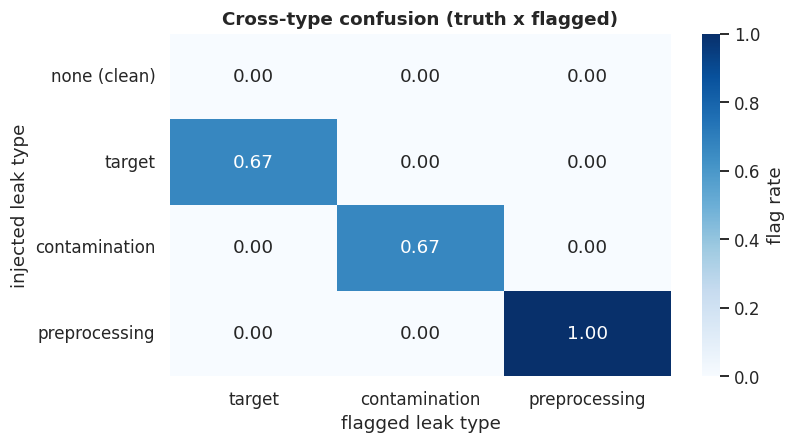


Blind spots: scenarios where the detection rate is below 50%

* target_L: detection rate 0.00 (n = 40, mean score 0.086)
  sigma = 1.0 makes the leak column only a weak label proxy (single-feature AUC ~ 0.76): no stronger than honest Adult features such as `relationship`, `marital_status` or `education_num`, so MI, single-feature strength and ablation cannot separate it from genuine signal. A data-only detector that stays quiet on clean data must miss it.

* contam_L: detection rate 0.00 (n = 40, mean score 0.404)
  1% of the test rows is statistically significant but small: s_dup = clip(0.01 / 0.02) = 0.5 caps the score near 0.8 * 0.5 = 0.4 plus a small memorisation term, i.e. just below the 0.5 threshold. Tiny contamination also inflates performance very little.


In [ ]:
# ===================================================================
# Cell 31 — Cross-type confusion and blind spots
# ===================================================================
res["truth_type"] = res["leak_type_true"].replace({"none": "none (clean)"})
type_order = ["none (clean)"] + list(CFG["EVALUATED_TYPES"])
flag_cols = {t: f"flag_{t}" for t in CFG["EVALUATED_TYPES"]}
conf_mat = (res.groupby("truth_type")[list(flag_cols.values())].mean().reindex(type_order))
conf_mat.columns = list(flag_cols)
print("Mean flag rate: rows = injected leak type, columns = flagged type (mean over seeds and models):")
display(conf_mat.round(3))
conf_mat.to_csv(os.path.join(TABLE_DIR, "cross_type_confusion.csv"))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(conf_mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "flag rate"})
ax.set_title("Cross-type confusion (truth x flagged)"); ax.set_xlabel("flagged leak type"); ax.set_ylabel("injected leak type")
plt.tight_layout(); plt.show()

EXPLAIN = {
    "target_L": "sigma = 1.0 makes the leak column only a weak label proxy (single-feature AUC ~ 0.76): no stronger than honest Adult features such as `relationship`, "
                "`marital_status` or `education_num`, so MI, single-feature strength and ablation cannot separate it from genuine signal. A data-only detector that stays quiet on clean data must miss it.",
    "target_M": "sigma = 0.5 gives a single-feature AUC ~ 0.92, above every honest Adult feature, so this leak is separable in principle; a miss means the calibrated threshold (cell 24) "
                "or the `a - 0.85` offset suppresses it (FPR/FNR trade-off).",
    "target_H": "sigma = 0.15 is a near-perfect label proxy; if this is missed, check the calibrated threshold (cell 24) and the model-level permutation share.",
    "contam_L": "1% of the test rows is statistically significant but small: s_dup = clip(0.01 / 0.02) = 0.5 caps the score near 0.8 * 0.5 = 0.4 plus a small "
                "memorisation term, i.e. just below the 0.5 threshold. Tiny contamination also inflates performance very little.",
    "contam_M": "5% contamination: near copies (perturbed by 0.005 std) can fall outside the nearest-neighbour radius eps (5% quantile of within-train NN distances), "
                "so the excess is under-counted when the data are dense.",
    "contam_H": "20% contamination should be detected; a miss points to a too-small NN radius (dense data) or an over-raised calibrated threshold.",
    "prep_L": "Scaler fingerprint relies on exact mean/std; it fails only if the processed data were re-rounded or re-scaled after the pipeline.",
    "prep_M": "Imputation fingerprint needs a visible spike of imputed values (1-80% of a column); without missing values there is nothing to fingerprint.",
    "prep_H": "Encoder fingerprint needs a frequency-encoded column with <= 10 distinct values in (0, 1].",
}
blind = by_scn[by_scn.detection_rate < 0.5].copy()
print("\nBlind spots: scenarios where the detection rate is below 50%")
if blind.empty:
    print("  none - every injected scenario is detected in at least half of the runs.")
for r in blind.itertuples():
    print(f"\n* {r.scenario}: detection rate {r.detection_rate:.2f} (n = {r.n}, mean score {r.mean_score:.3f})\n  {EXPLAIN.get(r.scenario, 'No pre-written explanation.')}")
# a second look at partial misses (50% <= rate < 90%)
partial = by_scn[(by_scn.detection_rate >= 0.5) & (by_scn.detection_rate < 0.9)]
if len(partial):
    print("\nPartial detection (50-90%):", {r.scenario: round(r.detection_rate, 2) for r in partial.itertuples()})

Validation-minus-test AUC gap per scenario (averaged over models and seeds):


,scenario,leak_type,mean_gap_val_minus_test,std,shift_vs_clean,p_value,exposed_by_validation
0,clean,none,-0.0016,0.0046,0.0000,NaN,False
1,target_L,target,-0.0007,0.0035,0.0009,0.0518,False
2,target_M,target,-0.0003,0.0017,0.0013,0.0535,False
3,target_H,target,0.0000,0.0000,0.0016,0.0313,False
4,contam_L,contamination,-0.0016,0.0046,0.0000,0.9384,False
5,contam_M,contamination,-0.0026,0.0047,-0.0010,0.0000,False
6,contam_H,contamination,-0.0055,0.0063,-0.0038,0.0000,True
7,prep_L,preprocessing,-0.0016,0.0047,0.0000,0.7621,False
8,prep_M,preprocessing,-0.0016,0.0046,0.0001,0.0965,False
9,prep_H,preprocessing,-0.0015,0.0046,0.0001,0.1183,False


By model:


model,logreg,mlp,rf,xgb
scenario,,,,
clean,-0.0019,-0.0016,-0.0016,-0.0013
target_L,-0.0006,-0.0007,-0.0007,-0.0010
target_M,-0.0004,-0.0001,-0.0005,-0.0003
target_H,0.0000,-0.0000,0.0000,0.0000
contam_L,-0.0019,-0.0011,-0.0021,-0.0014
contam_M,-0.0019,-0.0020,-0.0041,-0.0023
contam_H,-0.0020,-0.0028,-0.0128,-0.0043
prep_L,-0.0019,-0.0016,-0.0016,-0.0013
prep_M,-0.0019,-0.0015,-0.0015,-0.0013



Exposed by a held-out validation set : ['contam_H']
NOT exposed (validation shares the leak or the pipeline): ['target_L', 'target_M', 'target_H', 'contam_L', 'contam_M', 'prep_L', 'prep_M', 'prep_H']


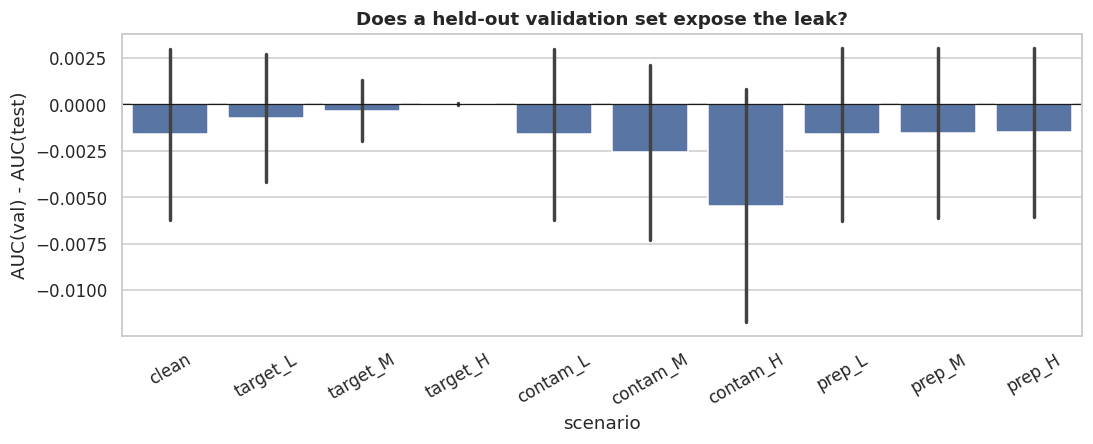

In [ ]:
# ===================================================================
# Cell 32 — Practitioner check: does a held-out VALIDATION set expose the leak?  (auc_val - auc_test)
#   contamination copies TEST rows into train, so validation is honest while the test score is inflated  -> gap < 0
#   target / preprocessing leaks are shared by validation (same column / same pipeline)                  -> gap ~ clean
#   (XGBoost uses the validation set for early stopping, which makes its val AUC very slightly optimistic.)
# ===================================================================
res["gap_val_test"] = res["auc_val"] - res["auc_test"]
clean_gap = res[res.scenario == "clean"].set_index(["seed", "model"])["gap_val_test"]
prac_rows = []
for sid in ACTIVE_SCENARIOS:
    sub = res[res.scenario == sid].set_index(["seed", "model"])["gap_val_test"]
    diff = (sub - clean_gap.reindex(sub.index)).dropna()
    p = stats.ttest_1samp(diff, 0.0).pvalue if (sid != "clean" and len(diff) > 2 and diff.std() > 0) else np.nan
    prac_rows.append(dict(scenario=sid, leak_type=CFG["SCENARIOS"][sid]["type"], mean_gap_val_minus_test=sub.mean(), std=sub.std(),
                          shift_vs_clean=diff.mean() if sid != "clean" else 0.0, p_value=p,
                          exposed_by_validation=bool(sid != "clean" and np.isfinite(p) and p < 0.01 and diff.mean() < -0.002)))
prac = pd.DataFrame(prac_rows)
print("Validation-minus-test AUC gap per scenario (averaged over models and seeds):")
display(prac.round(4))
print("By model:")
display(res.pivot_table(index="scenario", columns="model", values="gap_val_test", aggfunc="mean").reindex(ACTIVE_SCENARIOS).round(4))
exposed = prac[prac.exposed_by_validation].scenario.tolist()
hidden = prac[(prac.scenario != "clean") & (~prac.exposed_by_validation)].scenario.tolist()
print(f"\nExposed by a held-out validation set : {exposed or 'none'}")
print(f"NOT exposed (validation shares the leak or the pipeline): {hidden or 'none'}")
prac.to_csv(os.path.join(TABLE_DIR, "practitioner_val_vs_test.csv"), index=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=res, x="scenario", y="gap_val_test", order=ACTIVE_SCENARIOS, errorbar="sd", color="#4C72B0", ax=ax)
ax.axhline(0, color="k", lw=0.8); ax.set(ylabel="AUC(val) - AUC(test)", title="Does a held-out validation set expose the leak?")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

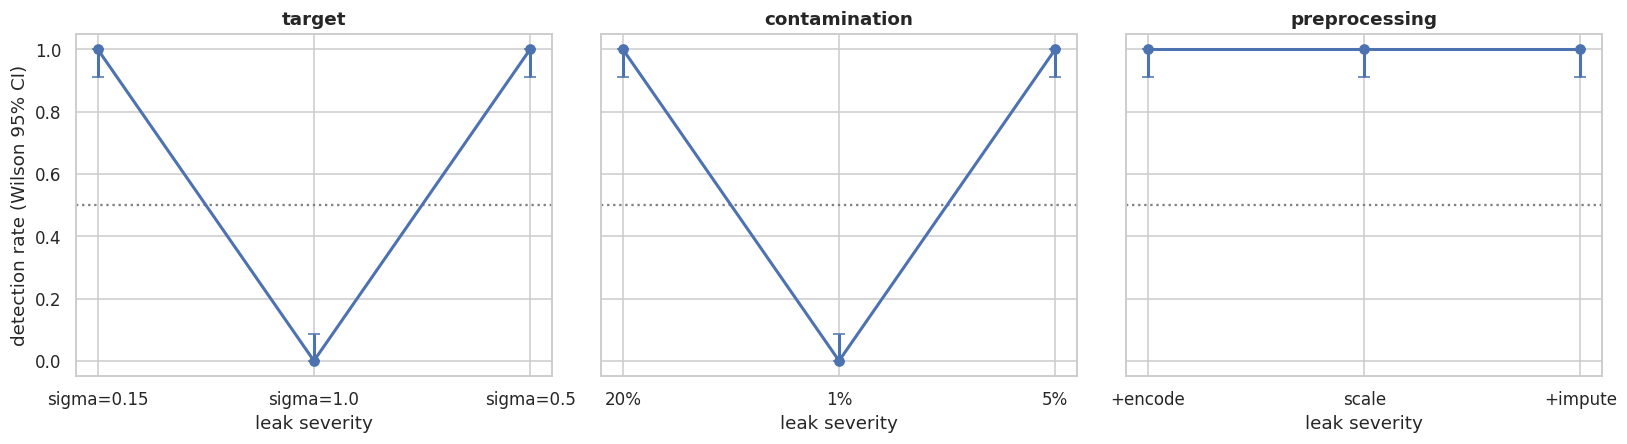

### Limits of pipeline-free detection (numbers from this run)
* **Target leakage**: detection rate falls from 1.00 at sigma = 0.15 to 0.00 at sigma = 1.0 (FNR 0.00 -> 1.00); mean AUC inflation shrinks from +0.0919 to +0.0254.
* **Tiny contamination** (1% of test rows, all exact): detection rate 0.00, FNR 1.00, true AUC inflation only +0.0004; at 20% the rate is 1.00 with +0.0041 AUC inflation.
* **Preprocessing leakage**: detection rates prep_L 1.00, prep_M 1.00, prep_H 1.00; true AUC inflation prep_L -0.00018, prep_M +0.00034, prep_H +0.00012 - essentially invisible to performance, but exactly fingerprinted in the processed arrays.


**Conclusion — what stays hidden, and why**

1. **Weak or subtle target leaks.** A noisy label proxy looks like any other legitimate predictive feature. From the data and a black box alone there is no way to tell *“this feature is informative”* from *“this feature was derived from the label”* — the detector can only say *“this feature is suspiciously strong”*. Thresholds that keep the clean-data false-positive rate at zero (cell 24) necessarily miss moderate leaks, and these are also the leaks that inflate performance least.
2. **Tiny contamination.** One percent of test rows duplicated in train is statistically detectable by exact hashing, but the evidence is small, the score saturates below the threshold, and the inflation it causes is small as well.
3. **Near-duplicates in dense data.** The nearest-neighbour radius is calibrated on honest within-train distances; in dense regions (many near-identical records) it shrinks, so slightly perturbed copies can fall outside it. Adult has many records with identical discrete attributes, which makes this visible.
4. **Preprocessing leakage is a blind spot for performance-based checks, not for fingerprints.** Because the processed arrays carry the exact fingerprint of the fit scope, the leak is found precisely — but only because the arrays are *exactly* what the pipeline produced (no re-rounding, no later re-scaling) and because there is a column to fingerprint (a scale step, an imputation spike, an encoded column). Its performance effect is near zero, so it cannot be seen through train/validation/test gaps.
5. **Temporal leakage cannot be assessed at all without a time axis.** Adult has none, so the detector abstains instead of guessing (see the Credit Card notebook for a dataset where it can be measured).


In [ ]:
# ===================================================================
# Cell 33 — Limits of pipeline-free detection: detection rate vs severity
# ===================================================================
SEV_LABEL = {"target": {"L": "sigma=1.0", "M": "sigma=0.5", "H": "sigma=0.15"},
             "contamination": {"L": "1%", "M": "5%", "H": "20%"},
             "preprocessing": {"L": "scale", "M": "+impute", "H": "+encode"},
             "temporal": {"L": "tau=2%", "M": "tau=10%", "H": "tau=20%"}}
n_types = len(CFG["EVALUATED_TYPES"])
fig, axes = plt.subplots(1, n_types, figsize=(5 * n_types, 4.2), sharey=True)
for ax, t in zip(np.atleast_1d(axes), CFG["EVALUATED_TYPES"]):
    sub = by_scn[by_scn.leak_type == t].sort_values("severity")
    xs = [SEV_LABEL[t][s] for s in sub.severity]
    lo = [wilson_ci(int(round(r * n)), n)[0] for r, n in zip(sub.detection_rate, sub.n)]
    hi = [wilson_ci(int(round(r * n)), n)[1] for r, n in zip(sub.detection_rate, sub.n)]
    ax.errorbar(range(len(xs)), sub.detection_rate, yerr=[sub.detection_rate - lo, np.array(hi) - sub.detection_rate], marker="o", capsize=4, lw=2)
    ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs); ax.set_ylim(-0.05, 1.05); ax.axhline(0.5, color="grey", ls=":")
    ax.set_title(t); ax.set_xlabel("leak severity")
np.atleast_1d(axes)[0].set_ylabel("detection rate (Wilson 95% CI)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "08_detection_vs_severity.png"), bbox_inches="tight"); plt.show()

rate = by_scn.set_index("scenario")["detection_rate"]
fnr = by_scn.set_index("scenario")["FNR"]
infl_by_scn = leaky.groupby("scenario")["infl_auc"].mean()
lines = []
if {"target_L", "target_H"} <= set(rate.index):
    lines.append(f"* **Target leakage**: detection rate falls from {rate['target_H']:.2f} at sigma = 0.15 to {rate['target_L']:.2f} at sigma = 1.0 "
                 f"(FNR {fnr['target_H']:.2f} -> {fnr['target_L']:.2f}); mean AUC inflation shrinks from {infl_by_scn['target_H']:+.4f} to {infl_by_scn['target_L']:+.4f}.")
if "contam_L" in rate.index:
    lines.append(f"* **Tiny contamination** (1% of test rows, all exact): detection rate {rate['contam_L']:.2f}, FNR {fnr['contam_L']:.2f}, "
                 f"true AUC inflation only {infl_by_scn['contam_L']:+.4f}; at 20% the rate is {rate.get('contam_H', float('nan')):.2f} with {infl_by_scn.get('contam_H', float('nan')):+.4f} AUC inflation.")
prep_ids = [s for s in ("prep_L", "prep_M", "prep_H") if s in rate.index]
if prep_ids:
    lines.append("* **Preprocessing leakage**: detection rates " + ", ".join(f"{s} {rate[s]:.2f}" for s in prep_ids)
                 + "; true AUC inflation " + ", ".join(f"{s} {infl_by_scn[s]:+.5f}" for s in prep_ids)
                 + " - essentially invisible to performance, but exactly fingerprinted in the processed arrays.")
tmp_ids = [s for s in ("temp_L", "temp_M", "temp_H") if s in rate.index]
if tmp_ids:
    lines.append("* **Temporal leakage**: detection rates " + ", ".join(f"{s} {rate[s]:.2f}" for s in tmp_ids)
                 + "; true AUC inflation " + ", ".join(f"{s} {infl_by_scn[s]:+.4f}" for s in tmp_ids)
                 + " - the overlap fingerprint is exact, but the performance effect of a small share of future rows is small.")
limits_summary = "\n".join(lines)
display(Markdown("### Limits of pipeline-free detection (numbers from this run)\n" + limits_summary))
display(Markdown("""
**Conclusion — what stays hidden, and why**

1. **Weak or subtle target leaks.** A noisy label proxy looks like any other legitimate predictive feature. From the data and a black box alone there is no way to tell *“this feature is informative”* from *“this feature was derived from the label”* — the detector can only say *“this feature is suspiciously strong”*. Thresholds that keep the clean-data false-positive rate at zero (cell 24) necessarily miss moderate leaks, and these are also the leaks that inflate performance least.
2. **Tiny contamination.** One percent of test rows duplicated in train is statistically detectable by exact hashing, but the evidence is small, the score saturates below the threshold, and the inflation it causes is small as well.
3. **Near-duplicates in dense data.** The nearest-neighbour radius is calibrated on honest within-train distances; in dense regions (many near-identical records) it shrinks, so slightly perturbed copies can fall outside it. Adult has many records with identical discrete attributes, which makes this visible.
4. **Preprocessing leakage is a blind spot for performance-based checks, not for fingerprints.** Because the processed arrays carry the exact fingerprint of the fit scope, the leak is found precisely — but only because the arrays are *exactly* what the pipeline produced (no re-rounding, no later re-scaling) and because there is a column to fingerprint (a scale step, an imputation spike, an encoded column). Its performance effect is near zero, so it cannot be seen through train/validation/test gaps.
5. **Temporal leakage cannot be assessed at all without a time axis.** Adult has none, so the detector abstains instead of guessing (see the Credit Card notebook for a dataset where it can be measured).
"""))
by_scn.to_csv(os.path.join(TABLE_DIR, "detection_by_scenario.csv"), index=False)

Detector on the combined leaky scenario: {'target': (0.826, True), 'contamination': (0.8, True), 'preprocessing': (1.0, True)}
Suspect features: ['leak_feat'] | reported duplicates: 976 exact + 559 near
Detector-guided remediation: removed 1535 duplicate rows and columns ['leak_feat'];  oracle remediation: 1952 rows and ['leak_feat'].
Train rows: leaky 29,274 -> detector-guided 27,749 | oracle 27,322 | clean 29,274

Test AUC (and AP) : clean baseline vs leaky vs remediated (seed 0):


,clean_baseline,leaky,remediated_detector_guided,remediated_oracle,ap_clean,ap_leaky,ap_detector_guided,ap_oracle,inflation_before,inflation_after (detector),inflation_after (oracle)
model,,,,,,,,,,,
Logistic Regression,0.8851,1.0,0.8853,0.8853,0.7353,1.0,0.7353,0.7352,0.1149,0.0002,0.0002
Random Forest,0.9160,1.0,0.9175,0.9155,0.8035,1.0,0.8058,0.8019,0.0840,0.0015,-0.0005
XGBoost,0.9284,1.0,0.9262,0.9285,0.8299,1.0,0.8237,0.8296,0.0716,-0.0022,0.0002
MLP,0.8999,1.0,0.9057,0.9059,0.7621,1.0,0.7698,0.7716,0.1001,0.0058,0.0060


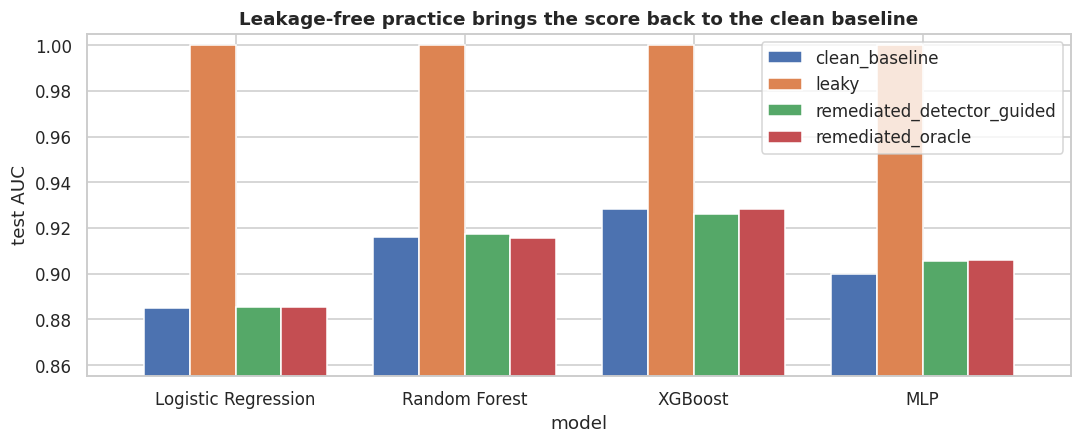

In [ ]:
# ===================================================================
# Cell 34 — Leakage-free practice demo
#   one leaky scenario with ALL leaks present -> detect -> remediate (de-duplicate, drop flagged features,
#   drop train rows from the test period or later, fit preprocessing on train only) -> re-train the 4 models
#   -> the score returns to the clean baseline
# ===================================================================
DEMO_SEED = 0
demo_scopes = dict(scale="pool", impute="pool", **({"encode": "pool"} if HAS_CATEGORICAL else {}))
demo_spec = dict(sigma=0.15, p=0.20, near_frac=0.5, scopes=demo_scopes, **({"tau": 0.20} if TS_COL else {}))
leaky_scn = build_from_spec(DEMO_SEED, demo_spec, "demo_all_leaks")
clean_demo = build_scenario(DEMO_SEED, "clean")

def remediate_arrays(scn, dup_train_ids, drop_cols, cut_time=None):
    """De-duplicate train, drop train rows from the test period or later, drop columns, refit ALL preprocessing on train only."""
    tr, va, te = scn.raw_train, scn.raw_val, scn.raw_test
    if len(dup_train_ids):
        tr = tr[~tr["row_id"].isin(set(dup_train_ids))]
    if cut_time is not None:
        tr = tr[tr[TS_COL] < cut_time]
    tr = tr.reset_index(drop=True)
    drop_cols = [c for c in drop_cols if c in tr.columns]
    tr, va, te = tr.drop(columns=drop_cols), va.drop(columns=drop_cols), te.drop(columns=drop_cols)
    pipe = Pipeline().fit(tr, te)                                        # every scope = train
    return ScenarioData(scenario_id="remediated", seed=scn.seed, X_train=pipe.transform(tr), y_train=tr["y"].to_numpy(),
                        X_val=pipe.transform(va), y_val=va["y"].to_numpy(), X_test=pipe.transform(te), y_test=te["y"].to_numpy(),
                        feature_names=list(pipe.feature_names), row_id_train=tr["row_id"].to_numpy(), row_id_test=te["row_id"].to_numpy(),
                        meta={}, truth={}, pipeline=pipe)

# detector on the leaky scenario (XGBoost as the black box)
bb_demo, met_demo = train_and_eval(leaky_scn, "xgb")
rep_demo = detector_for(leaky_scn, bb_demo, thresholds=CFG["THRESH"]).run()
flagged_demo = [t for t in CFG["EVALUATED_TYPES"] if rep_demo[t]["flag"]]
print("Detector on the combined leaky scenario:", {t: (round(rep_demo[t]["score"], 3), rep_demo[t]["flag"]) for t in CFG["EVALUATED_TYPES"]})
print("Suspect features:", rep_demo["target"]["evidence"]["suspect_features"], "| reported duplicates:",
      rep_demo["contamination"]["evidence"]["n_exact"], "exact +", rep_demo["contamination"]["evidence"]["n_near"], "near")

strip = lambda names: [n[:-5] if n.endswith("_freq") else n for n in names]
det_dup = rep_demo["contamination"]["evidence"]["dup_train_row_ids"] if rep_demo["contamination"]["flag"] else []
det_drop = strip(rep_demo["target"]["evidence"]["suspect_features"]) if rep_demo["target"]["flag"] else []
det_cut = rep_demo["temporal"]["evidence"].get("suggested_cut") if (TS_COL and rep_demo["temporal"]["flag"]) else None
orc_dup = list(leaky_scn.meta["contamination"]["dup_train_row_ids"]) + (list(leaky_scn.meta["temporal"]["future_row_ids"]) if TS_COL else [])
orc_drop = ["leak_feat"]
scn_detect = remediate_arrays(leaky_scn, det_dup, det_drop, det_cut)       # detector-guided remediation
scn_oracle = remediate_arrays(leaky_scn, orc_dup, orc_drop)                # ground-truth remediation (reference)
print(f"Detector-guided remediation: removed {len(det_dup)} duplicate rows" + (f", all train rows from t >= {det_cut:.0f}" if det_cut is not None else "")
      + f" and columns {det_drop or 'none'};  oracle remediation: {len(orc_dup)} rows and {orc_drop}.")
print(f"Train rows: leaky {len(leaky_scn.X_train):,} -> detector-guided {len(scn_detect.X_train):,} | oracle {len(scn_oracle.X_train):,} | clean {len(clean_demo.X_train):,}")

demo_rows = []
for name in CFG["MODELS"]:
    _, m_leaky = train_and_eval(leaky_scn, name)
    _, m_det = train_and_eval(scn_detect, name)
    _, m_orc = train_and_eval(scn_oracle, name)
    _, m_cl = train_and_eval(clean_demo, name)
    demo_rows.append(dict(model=MODEL_LABELS[name], clean_baseline=m_cl["auc_test"], leaky=m_leaky["auc_test"],
                          remediated_detector_guided=m_det["auc_test"], remediated_oracle=m_orc["auc_test"],
                          ap_clean=m_cl["ap_test"], ap_leaky=m_leaky["ap_test"], ap_detector_guided=m_det["ap_test"], ap_oracle=m_orc["ap_test"]))
demo = pd.DataFrame(demo_rows).set_index("model")
demo["inflation_before"] = demo["leaky"] - demo["clean_baseline"]
demo["inflation_after (detector)"] = demo["remediated_detector_guided"] - demo["clean_baseline"]
demo["inflation_after (oracle)"] = demo["remediated_oracle"] - demo["clean_baseline"]
print("\nTest AUC (and AP) : clean baseline vs leaky vs remediated (seed 0):")
display(demo.round(4))
demo.to_csv(os.path.join(TABLE_DIR, "remediation_demo.csv"))

ax = demo[["clean_baseline", "leaky", "remediated_detector_guided", "remediated_oracle"]].plot(kind="bar", figsize=(10, 4.2), width=0.8)
ax.set_ylim(max(0.5, demo[["clean_baseline", "leaky", "remediated_detector_guided", "remediated_oracle"]].min().min() - 0.03), 1.005)
ax.set_ylabel("test AUC"); ax.set_title("Leakage-free practice brings the score back to the clean baseline")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "09_remediation_demo.png"), bbox_inches="tight"); plt.show()


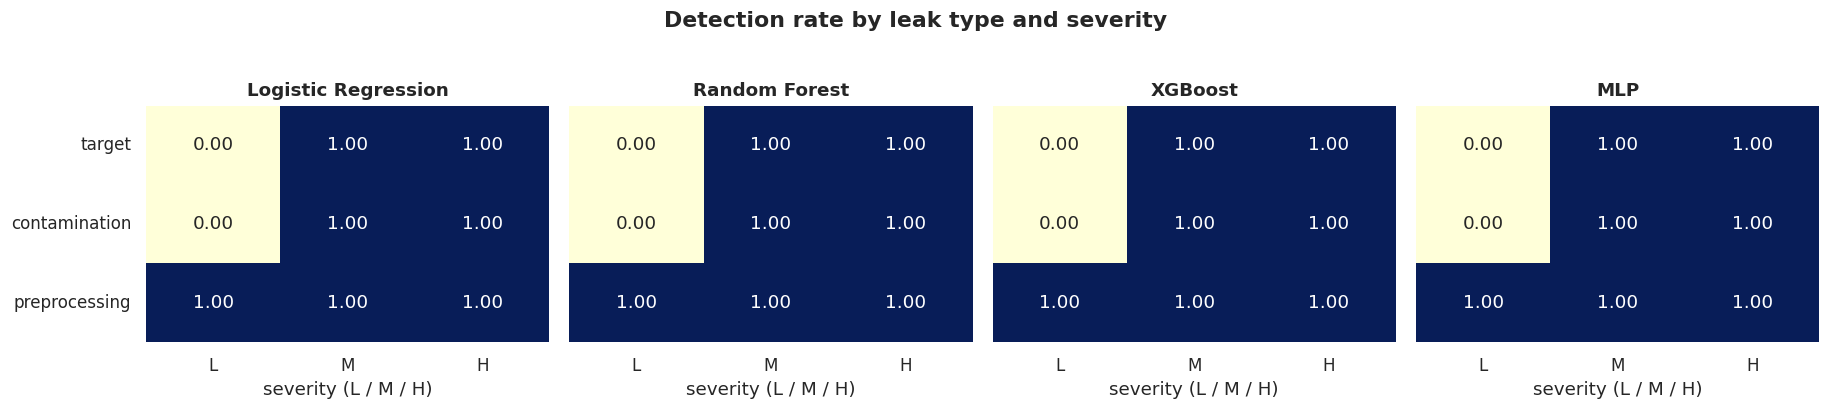

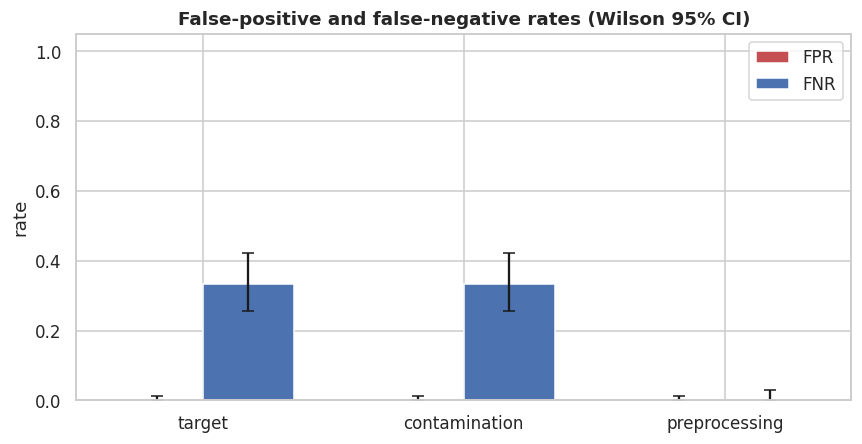

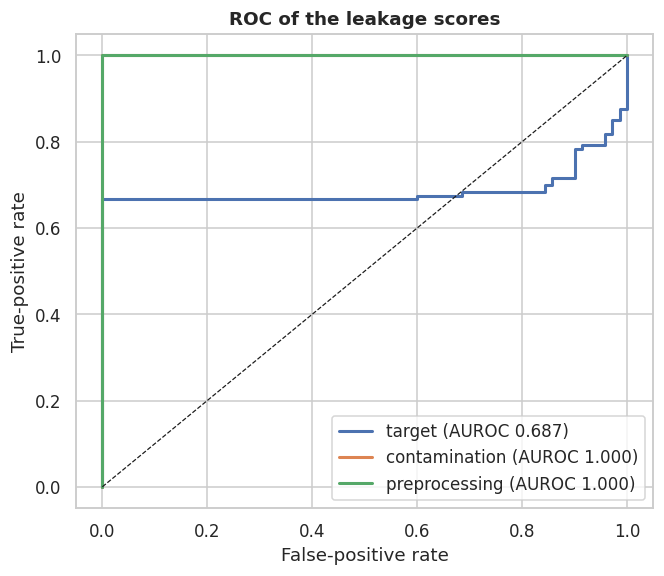

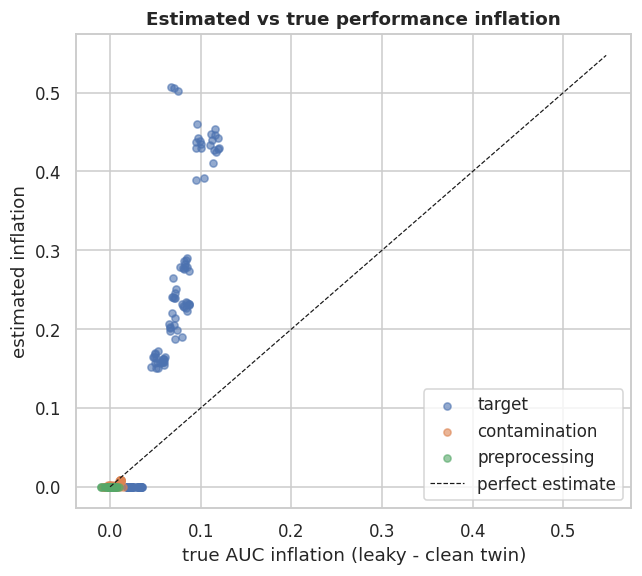

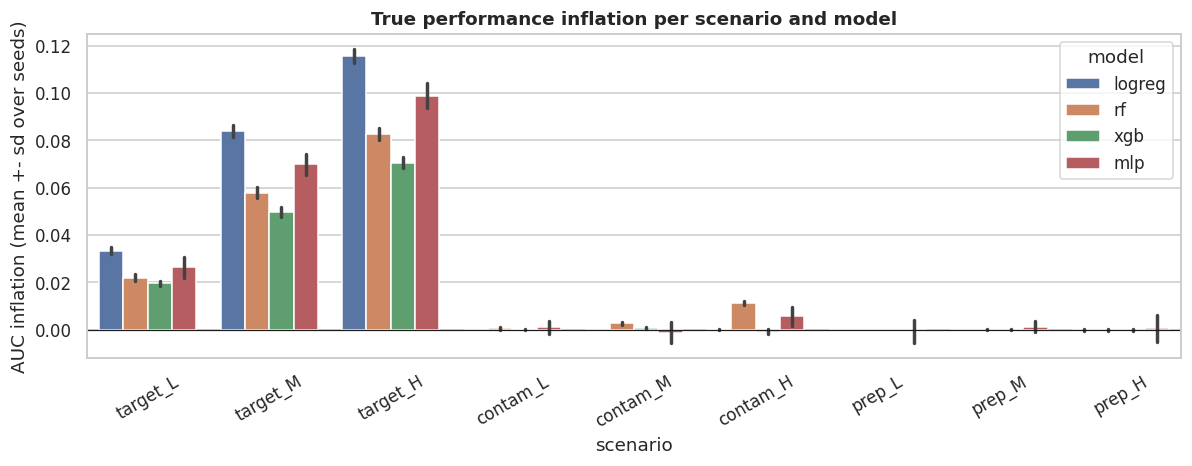

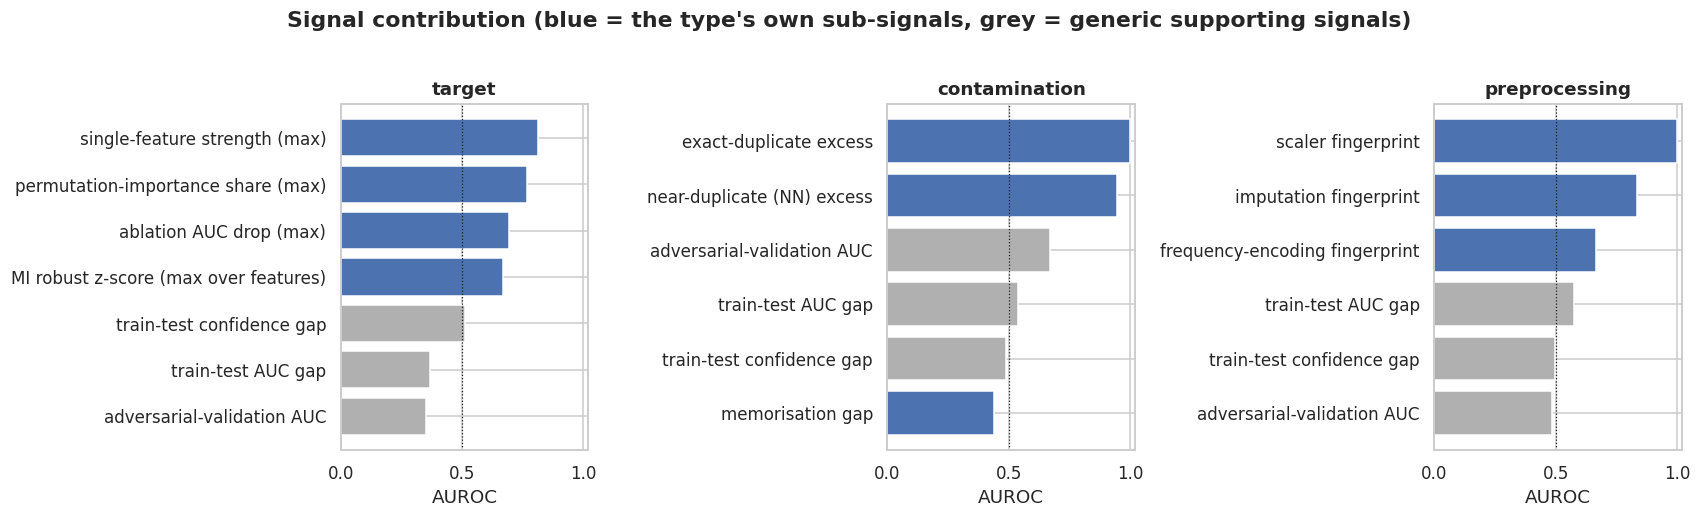

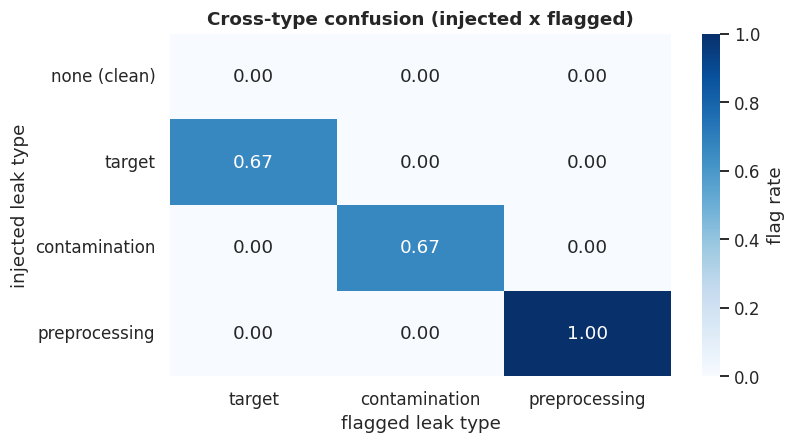

Figures saved to /content/results/figures : ['00_clean_baseline_roc.png', '00_eda.png', '01_detection_rate_heatmap.png', '02_fpr_fnr.png', '03_score_roc.png', '04_est_vs_true_inflation.png', '05_true_inflation_bars.png', '06_signal_contribution.png', '07_cross_type_confusion.png', '08_detection_vs_severity.png', '09_remediation_demo.png']


In [ ]:
# ===================================================================
# Cell 35 — Figures (PNG in results/figures/)
# ===================================================================
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); plt.show()

TYPES = CFG["EVALUATED_TYPES"]
SEVS = ["L", "M", "H"]

# 1. detection-rate heatmap (leak type x severity) per model
fig, axes = plt.subplots(1, len(CFG["MODELS"]), figsize=(4.2 * len(CFG["MODELS"]), 3.6), sharey=True)
for ax, m in zip(np.atleast_1d(axes), CFG["MODELS"]):
    grid = pd.DataFrame(index=TYPES, columns=SEVS, dtype=float)
    for sid in [s for s in ACTIVE_SCENARIOS if s != "clean"]:
        t, v = CFG["SCENARIOS"][sid]["type"], CFG["SCENARIOS"][sid]["variant"]
        sub = res[(res.scenario == sid) & (res.model == m)]
        grid.loc[t, v] = sub[f"flag_{t}"].mean()
    sns.heatmap(grid, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(MODEL_LABELS[m]); ax.set_xlabel("severity (L / M / H)"); ax.set_ylabel("")
fig.suptitle("Detection rate by leak type and severity", y=1.03, fontweight="bold")
savefig("01_detection_rate_heatmap.png")

# 2. FPR / FNR per type with Wilson CIs
fig, ax = plt.subplots(figsize=(8, 4.2))
w = 0.35
for k, (metric, colr) in enumerate([("FPR", "#C44E52"), ("FNR", "#4C72B0")]):
    vals = det_tbl.loc[TYPES, metric].to_numpy(float)
    lo, hi = det_tbl.loc[TYPES, f"{metric}_lo"].to_numpy(float), det_tbl.loc[TYPES, f"{metric}_hi"].to_numpy(float)
    ax.bar(np.arange(len(TYPES)) + (k - 0.5) * w, vals, w, yerr=[vals - lo, hi - vals], capsize=4, label=metric, color=colr)
ax.set_xticks(range(len(TYPES))); ax.set_xticklabels(TYPES); ax.set_ylim(0, 1.05); ax.set_ylabel("rate")
ax.set_title("False-positive and false-negative rates (Wilson 95% CI)"); ax.legend()
savefig("02_fpr_fnr.png")

# 3. ROC curves of the leakage scores
fig, ax = plt.subplots(figsize=(6.2, 5.4))
for t in TYPES:
    y = res[f"truth_{t}"].to_numpy(bool)
    if 0 < y.sum() < len(y):
        fpr, tpr, _ = roc_curve(y, res[f"score_{t}"])
        ax.plot(fpr, tpr, lw=2, label=f"{t} (AUROC {roc_auc_score(y, res[f'score_{t}']):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC of the leakage scores")
ax.legend(loc="lower right")
savefig("03_score_roc.png")

# 4. estimated vs true inflation
fig, ax = plt.subplots(figsize=(6, 5.4))
for t in TYPES:
    sub = leaky[leaky.leak_type_true == t]
    ax.scatter(sub["true_infl"], sub["est_own"], s=22, alpha=0.6, label=t)
lim = max(leaky["true_infl"].max(), leaky["est_own"].max(), 0.01) * 1.08
ax.plot([0, lim], [0, lim], "k--", lw=0.8, label="perfect estimate")
ax.set(xlabel="true AUC inflation (leaky - clean twin)", ylabel="estimated inflation", title="Estimated vs true performance inflation")
ax.legend()
savefig("04_est_vs_true_inflation.png")

# 5. true inflation bars per scenario x model
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.barplot(data=leaky, x="scenario", y="infl_auc", hue="model", order=[s for s in ACTIVE_SCENARIOS if s != "clean"],
            hue_order=CFG["MODELS"], errorbar="sd", ax=ax)
ax.axhline(0, color="k", lw=0.8); ax.set(ylabel="AUC inflation (mean +- sd over seeds)", title="True performance inflation per scenario and model")
plt.xticks(rotation=30)
savefig("05_true_inflation_bars.png")

# 6. signal contribution
fig, axes = plt.subplots(1, len(TYPES), figsize=(5.2 * len(TYPES), 4.6), sharex=True)
for ax, t in zip(np.atleast_1d(axes), TYPES):
    sub = sig_tbl[sig_tbl.leak_type == t].sort_values("AUROC")
    ax.barh(sub["signal"], sub["AUROC"], color=["#4C72B0" if r == "own" else "#B0B0B0" for r in sub["role"]])
    ax.axvline(0.5, color="k", lw=0.8, ls=":"); ax.set_xlim(0, 1.02); ax.set_title(t); ax.set_xlabel("AUROC")
fig.suptitle("Signal contribution (blue = the type's own sub-signals, grey = generic supporting signals)", y=1.02, fontweight="bold")
savefig("06_signal_contribution.png")

# 7. cross-type confusion
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(conf_mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "flag rate"})
ax.set(title="Cross-type confusion (injected x flagged)", xlabel="flagged leak type", ylabel="injected leak type")
savefig("07_cross_type_confusion.png")
print("Figures saved to", FIG_DIR, ":", sorted(os.listdir(FIG_DIR)))

In [ ]:
# ===================================================================
# Cell 36 — Export and conclusions
# ===================================================================
import shutil
# results.csv / results_with_inflation.csv / thresholds.json already live in RESULTS_DIR; the tables were saved by cells 27-34
pd.DataFrame([dict(scenario=s, **{f"score_{t}": g[f"score_{t}"].mean() for t in CFG["EVALUATED_TYPES"]},
                   **{f"flag_{t}": g[f"flag_{t}"].mean() for t in CFG["EVALUATED_TYPES"]}) for s, g in res.groupby("scenario")]
             ).to_csv(os.path.join(TABLE_DIR, "mean_scores_by_scenario.csv"), index=False)
zip_path = shutil.make_archive(os.path.join(ROOT, "leakage_results"), "zip", RESULTS_DIR)
print("Files in results/:", sorted(os.listdir(RESULTS_DIR)))
print("Tables:", sorted(os.listdir(TABLE_DIR)))
print("Zip archive:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)              # browser download only (no Google Drive)
except ImportError:
    print("(Not running in Colab: the zip stays at the path above.)")

# ---------- conclusions with the numbers of THIS run ----------
f = lambda x: "n/a" if not np.isfinite(x) else f"{x:.3f}"
lines = []
for t in CFG["EVALUATED_TYPES"]:
    r = det_tbl.loc[t]
    lines.append(f"| {t} | {f(r['accuracy'])} | {f(r['FPR'])} | {f(r['FNR'])} | {f(r['precision'])} | {f(r['recall'])} | "
                 f"{by_type_mean.get(t, float('nan')):+.4f} | {f(auroc_tbl.loc[t, 'AUROC'])} |")
ov = det_tbl.loc["OVERALL verdict"]
best_sig = {t: f"{best[t]['signal']} (AUROC {best[t]['AUROC']:.2f})" for t in CFG["EVALUATED_TYPES"]}
blind_txt = ", ".join(f"`{r.scenario}` ({r.detection_rate:.0%})" for r in blind.itertuples()) or "none"
rem = demo.loc[:, ["inflation_before", "inflation_after (detector)", "inflation_after (oracle)"]].mean()
display(Markdown(f"""
## Conclusions (numbers computed from this run: {len(CFG['EVAL_SEEDS'])} seeds x {len(ACTIVE_SCENARIOS)} scenarios x {len(CFG['MODELS'])} models = {len(res)} detector runs)

| leak type | accuracy | FPR | FNR | precision | recall | mean true AUC inflation | score AUROC |
|---|---|---|---|---|---|---|---|
{chr(10).join(lines)}
| **temporal** | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| **overall verdict (leaky vs clean)** | {f(ov['accuracy'])} | {f(ov['FPR'])} | {f(ov['FNR'])} | {f(ov['precision'])} | {f(ov['recall'])} | | |

* **Which signals mattered most.** Target: {best_sig['target']}; contamination: {best_sig['contamination']}; preprocessing: {best_sig['preprocessing']}. Adversarial validation and the train-test gaps are supporting signals only (weight 0); cell 29 shows how informative each is on its own.
* **Performance inflation.** Leak type ranking by mean true AUC inflation: {", ".join(f"{k} ({v:+.4f})" for k, v in by_type_mean.items())}. Preprocessing leakage barely changes any metric, so it is invisible to a train / validation / test comparison (cell 32) and is found only through exact fingerprints.
* **Limits of pipeline-free detection.** Blind spots in this run (detection rate < 50%): {blind_txt}. Weak or moderate target leaks are indistinguishable from legitimate strong features such as `relationship` or `education_num`; very small contamination is statistically visible but weak; near-duplicates depend on a data-adaptive radius. See cells 31 and 33.
* **Why temporal leakage was out of scope.** Adult has no timestamp, so the temporal module abstained (`score = NaN`, `flag = False`) and is excluded from accuracy / FPR / FNR. The module itself is verified on synthetic timestamps in cell 17, outside the reported results. No time axis was invented.
* **Leakage-free recommendations** (cell 34): de-duplicate before splitting and drop train rows that duplicate test rows; question any feature that is suspiciously predictive; fit **all** preprocessing (scaler, imputer, encoder) on the training split only. On the combined leaky scenario the mean AUC inflation of {rem['inflation_before']:+.4f} dropped to {rem['inflation_after (detector)']:+.4f} with detector-guided remediation ({rem['inflation_after (oracle)']:+.4f} with ground-truth remediation).
* **Caveats.** The `clean` scenario is clean only with respect to the four injected leak types; Wilson intervals treat runs as independent although the four models of a scenario share data-level evidence; results come from one dataset and three controlled injections, so rates should not be read as universal detector accuracy.
"""))


Files in results/: ['figures', 'results.csv', 'results_with_inflation.csv', 'run_config.json', 'tables', 'thresholds.json']
Tables: ['cross_type_confusion.csv', 'detection_by_scenario.csv', 'detection_by_type_model.csv', 'detection_metrics.csv', 'estimated_vs_true_inflation.csv', 'evidence_contamination.csv', 'evidence_target.csv', 'mean_scores_by_scenario.csv', 'practitioner_val_vs_test.csv', 'remediation_demo.csv', 'score_auroc.csv', 'signal_contribution.csv', 'true_inflation_acc.csv', 'true_inflation_ap.csv', 'true_inflation_auc.csv']
Zip archive: /content/leakage_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Conclusions (numbers computed from this run: 10 seeds x 10 scenarios x 4 models = 400 detector runs)

| leak type | accuracy | FPR | FNR | precision | recall | mean true AUC inflation | score AUROC |
|---|---|---|---|---|---|---|---|
| target | 0.900 | 0.000 | 0.333 | 1.000 | 0.667 | +0.0609 | 0.687 |
| contamination | 0.900 | 0.000 | 0.333 | 1.000 | 0.667 | +0.0017 | 1.000 |
| preprocessing | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | +0.0001 | 1.000 |
| **temporal** | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| **overall verdict (leaky vs clean)** | 0.800 | 0.000 | 0.222 | 1.000 | 0.778 | | |

* **Which signals mattered most.** Target: single-feature strength (max) (AUROC 0.81); contamination: exact-duplicate excess (AUROC 1.00); preprocessing: scaler fingerprint (AUROC 1.00). Adversarial validation and the train-test gaps are supporting signals only (weight 0); cell 29 shows how informative each is on its own.
* **Performance inflation.** Leak type ranking by mean true AUC inflation: target (+0.0609), contamination (+0.0017), preprocessing (+0.0001). Preprocessing leakage barely changes any metric, so it is invisible to a train / validation / test comparison (cell 32) and is found only through exact fingerprints.
* **Limits of pipeline-free detection.** Blind spots in this run (detection rate < 50%): `target_L` (0%), `contam_L` (0%). Weak or moderate target leaks are indistinguishable from legitimate strong features such as `relationship` or `education_num`; very small contamination is statistically visible but weak; near-duplicates depend on a data-adaptive radius. See cells 31 and 33.
* **Why temporal leakage was out of scope.** Adult has no timestamp, so the temporal module abstained (`score = NaN`, `flag = False`) and is excluded from accuracy / FPR / FNR. The module itself is verified on synthetic timestamps in cell 17, outside the reported results. No time axis was invented.
* **Leakage-free recommendations** (cell 34): de-duplicate before splitting and drop train rows that duplicate test rows; question any feature that is suspiciously predictive; fit **all** preprocessing (scaler, imputer, encoder) on the training split only. On the combined leaky scenario the mean AUC inflation of +0.0926 dropped to +0.0013 with detector-guided remediation (+0.0015 with ground-truth remediation).
* **Caveats.** The `clean` scenario is clean only with respect to the four injected leak types; Wilson intervals treat runs as independent although the four models of a scenario share data-level evidence; results come from one dataset and three controlled injections, so rates should not be read as universal detector accuracy.
